# Notebook 1: Dataset y preprocesamiento
**Trabajo Práctico: Sistema de Reconocimiento Facial**

Visión por Computadora.

Tecnicatura Universitaria en Inteligencia Artificial

(FCEIA, UNR).



## Alumno
Marco Ippolito

## Objetivo de esta notebook
Elegir, analizar y limpiar el dataset de rostros, detectar y alinear las caras, explorar los datos con clustering, definir la augmentation y generar los splits (train / validation / test) que va a usar la notebook 2 para entrenar y comparar modelos.

## 0. Preparación del entorno

### 0.1 Montar Google Drive
Colab borra todos los archivos al cerrar la sesión. Por eso se guarda el dataset, los modelos y los resultados en Google Drive, dentro de la carpeta `TP_FaceRec`. Esta celda conecta Drive y crea esa carpeta si todavía no existe.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
BASE = '/content/drive/MyDrive/TP_FaceRec'  # carpeta del TP en Drive
os.makedirs(BASE, exist_ok=True)

Mounted at /content/drive


### 0.2 Instalación de librerías
Se instalan las librerías que Colab no trae por defecto:
- **insightface**: detector de rostros (SCRFD) y modelo de reconocimiento (ArcFace).
- **onnxruntime-gpu**: ejecuta los modelos `.onnx` en la GPU, para procesar las ~17.500 imágenes en minutos en lugar de casi una hora.
- **albumentations**: data augmentation (sección 6).
- **onnx2torch**: convierte el modelo ArcFace `.onnx` a PyTorch para ejecutarlo en la GPU (ver 0.5).

In [ ]:
!pip install -q insightface==0.7.3 onnxruntime-gpu albumentations
!pip install -q insightface==0.7.3 onnxruntime-gpu albumentations onnx2torch

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


### 0.2 Instalación de librerías
Se instalan las librerías que Colab no trae por defecto:
- **insightface**: detector de rostros (SCRFD) y modelo de reconocimiento (ArcFace).
- **onnxruntime-gpu**: ejecuta los modelos `.onnx` en la GPU, para procesar las ~17.500 imágenes en minutos en lugar de casi una hora. Se desinstala antes la versión solo-CPU, porque comparten el mismo nombre de módulo y entran en conflicto.
- **albumentations**: data augmentation (sección 6).

### 0.3 Clonar el repositorio del grupo
Cloné el fork (rama `feature/tp-reconocimiento-facial`) y agregamos `src/` al path de Python. Así la notebook importa **el mismo módulo `face_pipeline.py` que usa el backend**, y la detección, la alineación y la normalización son idénticas en la notebook y en la app. Con esto evitamos el error más frecuente: que el modelo funcione en la notebook pero no en la app por preprocesar distinto.

In [ ]:
REPO_URL = 'https://github.com/MarcoIppolito96/Aplicacion-Reconocimiento-Facial'
REPO = f'{BASE}/repo'

if not os.path.exists(REPO):
    !git clone -b feature/tp-reconocimiento-facial {REPO_URL} {REPO}
else:
    !git -C {REPO} pull  # si ya estaba clonado, trae los últimos cambios

import sys
sys.path.insert(0, f'{REPO}/src')  # para importar el mismo código que usa la app

Already up to date.


### 0.4 Descarga de modelos preentrenados (InsightFace `buffalo_l`)
Descargamos el paquete `buffalo_l` de InsightFace, del cual usamos dos archivos:
- `det_10g.onnx`: detector **SCRFD**. Encuentra las caras y devuelve su caja y 5 puntos clave (ojos, nariz y comisuras de la boca).
- `w600k_r50.onnx`: reconocedor **ArcFace** (ResNet-50). Convierte una cara alineada en un embedding de 512 números.

Se descargan una sola vez y quedan guardados en Drive.
**Licencia:** los modelos de InsightFace son de uso no comercial / de investigación, lo que es compatible con un trabajo académico.

In [ ]:
MODELOS = f'{BASE}/models'
if not os.path.exists(f'{MODELOS}/w600k_r50.onnx'):
    !wget -q https://github.com/deepinsight/insightface/releases/download/v0.7/buffalo_l.zip -O /content/buffalo_l.zip
    !unzip -q -o /content/buffalo_l.zip -d {MODELOS}
!ls -lh {MODELOS}

total 326M
-rw------- 1 root root 137M Sep 20  2021 1k3d68.onnx
-rw------- 1 root root 4.8M Sep 20  2021 2d106det.onnx
-rw------- 1 root root  17M Sep 20  2021 det_10g.onnx
-rw------- 1 root root 1.3M Sep 20  2021 genderage.onnx
-rw------- 1 root root 167M Sep 20  2021 w600k_r50.onnx


### 0.5 Carga de modelos y prueba del pipeline completo
- **Detector (SCRFD):** se ejecuta con onnxruntime en la GPU.
- **ArcFace:** el mismo archivo `w600k_r50.onnx` que usa la app se convierte a PyTorch con `onnx2torch` y se ejecuta en la GPU. En este entorno, onnxruntime-gpu no pudo ejecutar ArcFace por una incompatibilidad con la versión de cuDNN de Colab. Se verifica que los embeddings coinciden con los de onnxruntime (diferencia del orden de 1e-7), así que el modelo es exactamente el mismo que usa la app.

Con una imagen de ejemplo (6 personas) se verifica todo el recorrido de una cara: **detectar → alinear → preprocesar → embedding**.
1. **Detectar:** SCRFD encuentra cada cara y sus 5 landmarks.
2. **Alinear:** con los landmarks se aplica una transformación de similitud hacia una plantilla de referencia (`norm_crop`), que deja ojos, nariz y boca siempre en la misma posición, en un recorte de 112×112.
3. **Preprocesar:** BGR → RGB, píxeles escalados a [-1, 1] y formato `(N, 3, 112, 112)`.
4. **Embedding:** ArcFace genera un vector de 512 números normalizado L2 (norma 1). Así la similitud coseno entre dos caras es un producto punto.

Detector en: CUDAExecutionProvider | ArcFace en: cuda
Caras detectadas: 6


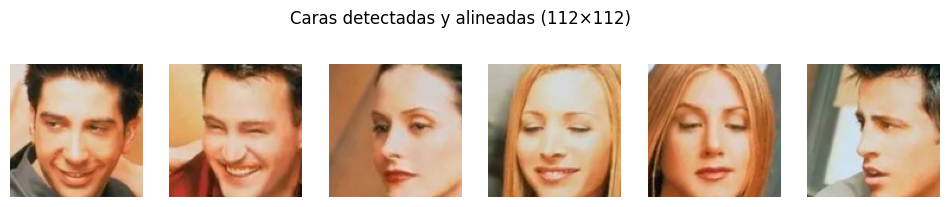

Embeddings: (6, 512) | normas = [1. 1. 1. 1. 1. 1.]
Diferencia máxima PyTorch vs. onnxruntime: 3.8e-07


In [ ]:
import cv2, numpy as np, matplotlib.pyplot as plt, insightface, torch
from onnx2torch import convert
from lib import face_pipeline as fp

dispositivo = 'cuda' if torch.cuda.is_available() else 'cpu'

# Detector SCRFD con onnxruntime en GPU: cajas + 5 landmarks
detector = fp.cargar_detector(f'{MODELOS}/det_10g.onnx', usar_gpu=True)

# ArcFace: el mismo .onnx que usa la app, convertido a PyTorch para correr en GPU
arcface = convert(f'{MODELOS}/w600k_r50.onnx').eval().to(dispositivo)
print('Detector en:', detector.session.get_providers()[0], '| ArcFace en:', dispositivo)

@torch.no_grad()
def embeddings_arcface(caras_bgr, tamanio_lote=128):
    """Caras alineadas BGR -> embeddings (N, 512) normalizados L2, por lotes."""
    salida = []
    for i in range(0, len(caras_bgr), tamanio_lote):
        # Mismo preprocesamiento que la app (fp.preprocesar)
        lote = torch.from_numpy(np.concatenate([fp.preprocesar(c) for c in caras_bgr[i:i + tamanio_lote]])).to(dispositivo)
        salida.append(torch.nn.functional.normalize(arcface(lote), dim=1).cpu().numpy())
    return np.concatenate(salida)

# Prueba con una imagen de ejemplo
img = cv2.imread(os.path.join(os.path.dirname(insightface.__file__), 'data/images/t1.jpg'))
caras = fp.detectar(detector, img)
print(f'Caras detectadas: {len(caras)}')

alineadas = [fp.alinear(img, landmarks) for _, _, landmarks in caras]
fig, axes = plt.subplots(1, len(alineadas), figsize=(2 * len(alineadas), 2.5))
for ax, cara in zip(axes, alineadas):
    ax.imshow(cv2.cvtColor(cara, cv2.COLOR_BGR2RGB)); ax.axis('off')  # BGR→RGB solo para mostrar
plt.suptitle('Caras detectadas y alineadas (112×112)'); plt.show()

embeddings = embeddings_arcface(alineadas)
print(f'Embeddings: {embeddings.shape} | normas = {np.linalg.norm(embeddings, axis=1).round(3)}')

# Verificación: PyTorch da los mismos embeddings que onnxruntime (lo que usa la app)
emb_app = fp.calcular_embeddings(fp.cargar_reconocedor(f'{MODELOS}/w600k_r50.onnx'), alineadas)
print(f'Diferencia máxima PyTorch vs. onnxruntime: {np.abs(embeddings - emb_app).max():.1e}')

## 1. Dataset: Pins Face Recognition
Descargamos el dataset **Pins Face Recognition** desde Kaggle (`hereisburak/pins-face-recognition`): unas 105 celebridades con varias decenas de fotos cada una, extraídas de Pinterest.

El token de Kaggle se guarda en los *Secrets* de Colab y no aparece en la notebook. El `.zip` se guarda una sola vez en Drive, y en cada sesión se descomprime en el disco local de Colab (`/content`), que es mucho más rápido que leer miles de archivos chicos desde Drive.

In [ ]:
from google.colab import userdata
os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN')  # token desde Secrets, no queda en la notebook
!pip install -q -U kaggle

ZIP_PINS = f'{BASE}/datos/pins.zip'
os.makedirs(f'{BASE}/datos', exist_ok=True)

if not os.path.exists(ZIP_PINS):  # se descarga una sola vez a Drive
    !kaggle datasets download -d hereisburak/pins-face-recognition -p /content
    !cp /content/pins-face-recognition.zip "{ZIP_PINS}"

DATOS = '/content/pins'  # copia local, rápida
if not os.path.exists(DATOS):
    !unzip -q "{ZIP_PINS}" -d {DATOS}
!ls {DATOS}

105_classes_pins_dataset


In [ ]:
from pathlib import Path

# Busca la carpeta que contiene las subcarpetas "pins_<Nombre>"
carpeta_raiz = next(p.parent for p in Path(DATOS).rglob('pins_*') if p.is_dir())
carpetas = sorted(p for p in carpeta_raiz.iterdir() if p.is_dir())

print(f'Carpeta raíz: {carpeta_raiz}')
print(f'Identidades: {len(carpetas)}')
print(f'Imágenes totales: {sum(len(list(c.glob("*"))) for c in carpetas)}')
print('Ejemplos:', [c.name.replace("pins_", "") for c in carpetas[:5]])

Carpeta raíz: /content/pins/105_classes_pins_dataset
Identidades: 105
Imágenes totales: 17534
Ejemplos: ['Adriana Lima', 'Alex Lawther', 'Alexandra Daddario', 'Alvaro Morte', 'Amanda Crew']


## 2. Análisis exploratorio (EDA)
Antes de usar el dataset, se analizó para conocer sus características y detectar posibles problemas:
- **Cantidad de imágenes por identidad**, para medir el desbalance de clases.
- **Resoluciones y relación de aspecto**, para detectar imágenes demasiado chicas para el tamaño objetivo de 112×112.
- **Formato y canales**: extensiones, imágenes en escala de grises y archivos corruptos.
- **Muestra visual** por identidad.
- **Iluminación**: distribución de brillo y contraste.

Primero recorro todas las imágenes una vez y guardo sus características en una tabla (DataFrame).

In [ ]:
import pandas as pd
from tqdm.auto import tqdm

filas = []
for carpeta in tqdm(carpetas, desc='Identidades'):
    identidad = carpeta.name.replace('pins_', '')
    for ruta in sorted(carpeta.iterdir()):
        img = cv2.imread(str(ruta))  # BGR uint8, o None si el archivo no abre
        fila = {'ruta': str(ruta), 'identidad': identidad, 'extension': ruta.suffix.lower(), 'legible': img is not None}
        if img is not None:
            gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
            # Foto en blanco y negro guardada como color: los 3 canales son casi iguales
            dif_canales = np.abs(img[..., 0].astype(int) - img[..., 2].astype(int)).mean()
            fila.update(alto=img.shape[0], ancho=img.shape[1], es_gris=dif_canales < 2,
                        brillo=gris.mean(), contraste=gris.std())
        filas.append(fila)

df = pd.DataFrame(filas)
df.to_csv(f'{BASE}/datos/eda_pins.csv', index=False)  # la guardamos para no recalcular
df.head()

Identidades:   0%|          | 0/105 [00:00<?, ?it/s]

,ruta,identidad,extension,legible,alto,ancho,es_gris,brillo,contraste
0,/content/pins/105_classes_pins_dataset/pins_Ad...,Adriana Lima,.jpg,True,668,550,False,106.710637,80.191789
1,/content/pins/105_classes_pins_dataset/pins_Ad...,Adriana Lima,.jpg,True,320,302,False,117.535617,67.988482
2,/content/pins/105_classes_pins_dataset/pins_Ad...,Adriana Lima,.jpg,True,155,146,False,99.327397,73.473677
3,/content/pins/105_classes_pins_dataset/pins_Ad...,Adriana Lima,.jpg,True,225,209,False,80.838767,51.969106
4,/content/pins/105_classes_pins_dataset/pins_Ad...,Adriana Lima,.jpg,True,108,102,False,80.183279,56.960489


**Resultado:** Se recorrieron las 105 identidades y se guardó una fila por imagen con su ruta, identidad, extensión, si se puede abrir, tamaño (alto × ancho), si es blanco y negro, brillo y contraste. Ya en las primeras filas se ve que **los tamaños varían mucho**: de 668×550 a 108×102 px, incluso dentro de la misma persona. Esta tabla se guarda en Drive (`eda_pins.csv`) y es la base de todo el análisis que sigue.

### 2.1 Cantidad de imágenes por identidad
Se cuenta cuántas fotos tiene cada persona para medir el **desbalance de clases**: si algunas personas tienen muchas más fotos que otras, el modelo tiende a aprender mejor a esas.

count    105.0
mean     167.0
std       34.1
min       86.0
25%      141.0
50%      169.0
75%      192.0
max      237.0

Relación mayor / menor: 2.8x


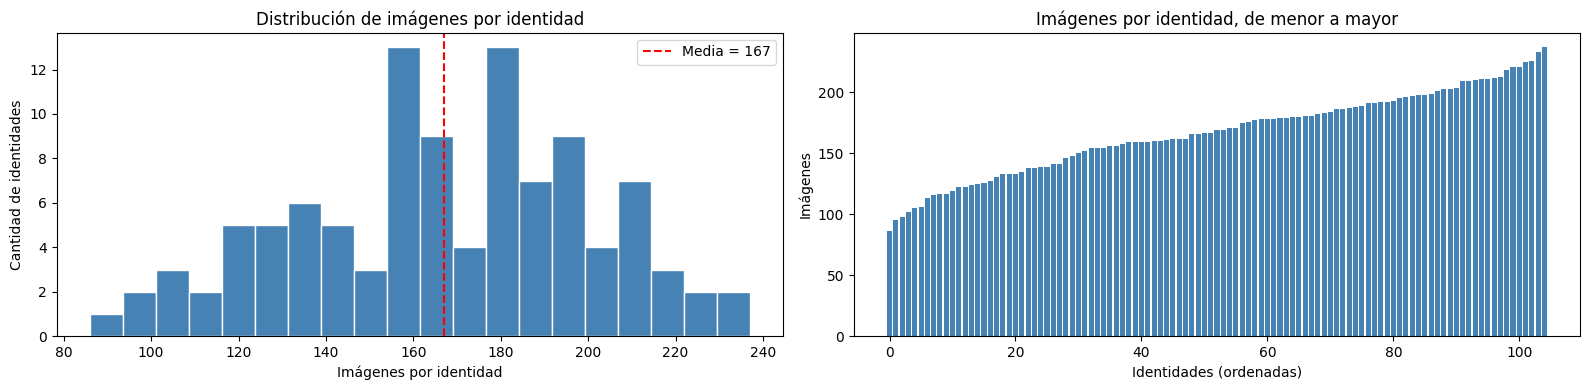


Las 5 con menos imágenes:
 identidad
Lionel Messi          86
Mark Zuckerberg       95
Cristiano Ronaldo     98
Brian J. Smith       102
Morgan Freeman       105

Las 5 con más imágenes:
 identidad
elizabeth olsen       221
Alexandra Daddario    225
Katherine Langford    226
Robert Downey Jr      233
Leonardo DiCaprio     237


In [ ]:
conteo = df.groupby('identidad').size().sort_values()

print(conteo.describe().round(1).to_string())
print(f'\nRelación mayor / menor: {conteo.max() / conteo.min():.1f}x')

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
axes[0].hist(conteo, bins=20, color='steelblue', edgecolor='white')
axes[0].axvline(conteo.mean(), color='red', ls='--', label=f'Media = {conteo.mean():.0f}')
axes[0].set_xlabel('Imágenes por identidad'); axes[0].set_ylabel('Cantidad de identidades')
axes[0].set_title('Distribución de imágenes por identidad'); axes[0].legend()

axes[1].bar(range(len(conteo)), conteo.values, color='steelblue')
axes[1].set_xlabel('Identidades (ordenadas)'); axes[1].set_ylabel('Imágenes')
axes[1].set_title('Imágenes por identidad, de menor a mayor')
plt.tight_layout(); plt.show()

print('\nLas 5 con menos imágenes:\n', conteo.head().to_string())
print('\nLas 5 con más imágenes:\n', conteo.tail().to_string())

**Resultado:** el dataset tiene **105 identidades** y unas **17.500 imágenes** (167 por persona en promedio, mediana 169).
- **Mínimo:** 86 imágenes (Lionel Messi). **Máximo:** 237 (Leonardo DiCaprio).
- La relación entre la identidad con más fotos y la que tiene menos es de **2,8x**.

**Interpretación:** existe un **desbalance moderado**. Ninguna clase está subrepresentada al extremo: incluso la más chica tiene 86 imágenes, que alcanzan para entrenar una CNN. Como comparación, en LFW la mayoría de las personas tiene una sola foto y la relación supera las 500x. Esto **confirma la elección de Pins** frente a LFW.

Igualmente, para que el modelo no favorezca a las identidades con más fotos, en el entrenamiento se va a evaluar compensar el desbalance con *class weights* o *weighted sampling*.

### 2.2 Resoluciones y relación de aspecto
El modelo trabaja con caras de 112×112 px. Si la imagen completa es más chica que eso, la cara que contiene es todavía más chica y pierde detalle. Se analiza la distribución de tamaños y cuántas imágenes quedan por debajo de ese umbral.

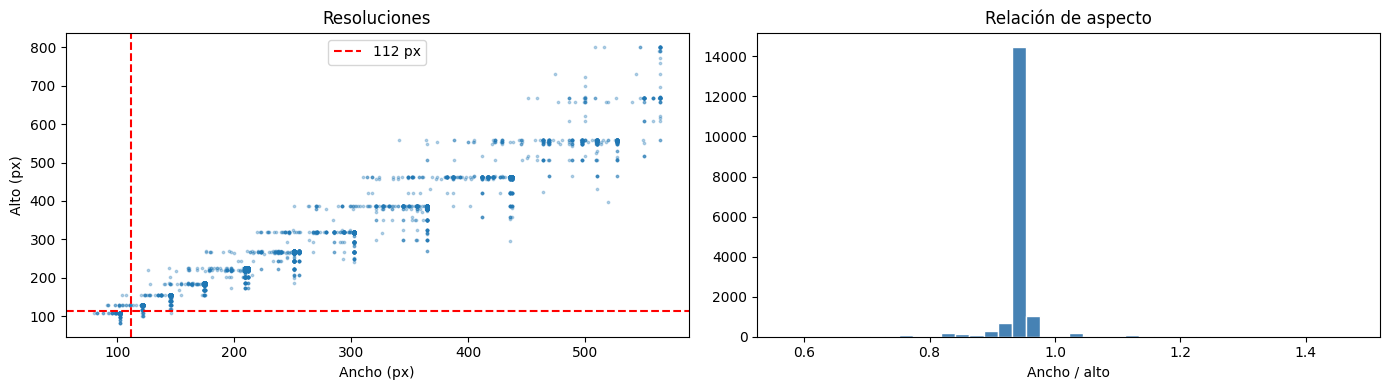

         ancho     alto
count  17534.0  17534.0
mean     211.0    226.0
std      102.0    113.0
min       80.0     82.0
25%      122.0    129.0
50%      175.0    185.0
75%      255.0    268.0
max      564.0    802.0

Imágenes con algún lado menor a 112 px: 2626 (15.0%)


In [ ]:
ok = df[df['legible']].copy()  # solo imágenes que se pudieron abrir
ok['aspecto'] = ok['ancho'] / ok['alto']

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].scatter(ok['ancho'], ok['alto'], s=3, alpha=0.3)
axes[0].axvline(112, color='red', ls='--'); axes[0].axhline(112, color='red', ls='--', label='112 px')
axes[0].set_xlabel('Ancho (px)'); axes[0].set_ylabel('Alto (px)'); axes[0].set_title('Resoluciones'); axes[0].legend()

axes[1].hist(ok['aspecto'], bins=40, color='steelblue', edgecolor='white')
axes[1].set_xlabel('Ancho / alto'); axes[1].set_title('Relación de aspecto')
plt.tight_layout(); plt.show()

print(ok[['ancho', 'alto']].describe().round(0).to_string())
chicas = ok[(ok['ancho'] < 112) | (ok['alto'] < 112)]
print(f'\nImágenes con algún lado menor a 112 px: {len(chicas)} ({len(chicas) / len(ok):.1%})')

**Resultado:**
- Tamaño mediano: **175 × 185 px**. El rango va de 80 × 82 px a 564 × 802 px.
- La relación de aspecto está concentrada en **≈ 0,94** (casi cuadrada) en la gran mayoría de las imágenes.
- **2.626 imágenes (15%)** tienen algún lado menor a 112 px.

**Interpretación:**
- La relación de aspecto tan uniforme muestra que **Pins ya viene con los rostros pre-recortados**: la cara ocupa casi toda la imagen. Por lo tanto, el tamaño de la imagen es aproximadamente el tamaño de la cara.
- El 15% de imágenes menores a 112 px **no se descarta automáticamente**. Son apenas más chicas que el objetivo (mínimo 80 px), y al redimensionarlas a 112×112 pierden algo de nitidez, pero conservan los rasgos. Descartarlas eliminaría una de cada siete imágenes.
- El filtro por tamaño se aplica en la etapa de limpieza (sección 3) sobre el **tamaño de la cara detectada** (*bounding box* menor a 40 px de lado, como sugiere el enunciado), que es lo que realmente importa, y no sobre el tamaño de la imagen.
- Al estar las caras tan recortadas, el detector puede tener menos contexto alrededor del rostro. Esto se tiene en cuenta en la sección 3.

### 2.3 Formato, canales y archivos corruptos
Se verifica qué extensiones hay, si existen archivos que no se pueden abrir y cuántas imágenes están en blanco y negro. Una foto en blanco y negro guardada como color tiene sus 3 canales prácticamente iguales.

Extensiones:
 extension
.jpg    17534

Archivos que no se pueden abrir: 0
Imágenes en blanco y negro: 1279 (7.3%)


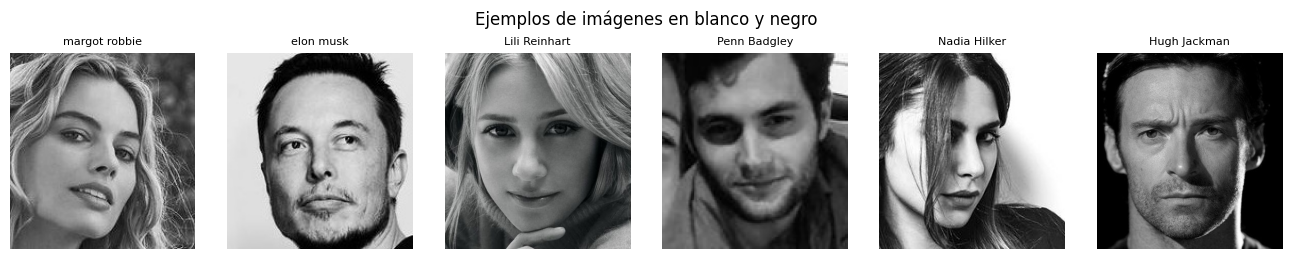

In [ ]:
print('Extensiones:\n', df['extension'].value_counts().to_string())
print(f'\nArchivos que no se pueden abrir: {(~df["legible"]).sum()}')
print(f'Imágenes en blanco y negro: {ok["es_gris"].sum()} ({ok["es_gris"].mean():.1%})')

# Ejemplos de imágenes en blanco y negro
grises = ok[ok['es_gris']].sample(min(6, ok['es_gris'].sum()), random_state=42)
fig, axes = plt.subplots(1, len(grises), figsize=(2.2 * len(grises), 2.6))
for ax, (_, r) in zip(np.atleast_1d(axes), grises.iterrows()):
    ax.imshow(cv2.cvtColor(cv2.imread(r['ruta']), cv2.COLOR_BGR2RGB)); ax.set_title(r['identidad'], fontsize=8); ax.axis('off')
plt.suptitle('Ejemplos de imágenes en blanco y negro'); plt.tight_layout(); plt.show()

**Resultado:**
- Todas las imágenes son **`.jpg`** (17.534).
- **No hay archivos corruptos**: todas se pueden abrir.
- **1.279 imágenes (7,3%) están en blanco y negro**, aunque guardadas con 3 canales.

**Interpretación:**
- Al ser todo `.jpg` y sin archivos rotos, no hace falta unificar formatos ni descartar archivos por este motivo.
- Las imágenes en blanco y negro **se conservan**. Son fotos reales que también pueden aparecer en uso (por ejemplo, fotos antiguas o con filtros), y como ya tienen 3 canales, entran al modelo sin cambios.
- Igualmente, son un tipo de captura distinto y podrían formar **sub-grupos** dentro de una misma identidad. Esto se verifica en el clustering.
- Para que el modelo no dependa del color para reconocer a una persona, se puede incluir una conversión aleatoria a escala de grises en la augmentation

### 2.4 Muestra visual por identidad
Se muestran 6 imágenes al azar de 6 identidades, para observar la variabilidad dentro de una misma persona: pose, iluminación, expresión, edad, maquillaje y oclusiones (anteojos, manos, pelo).

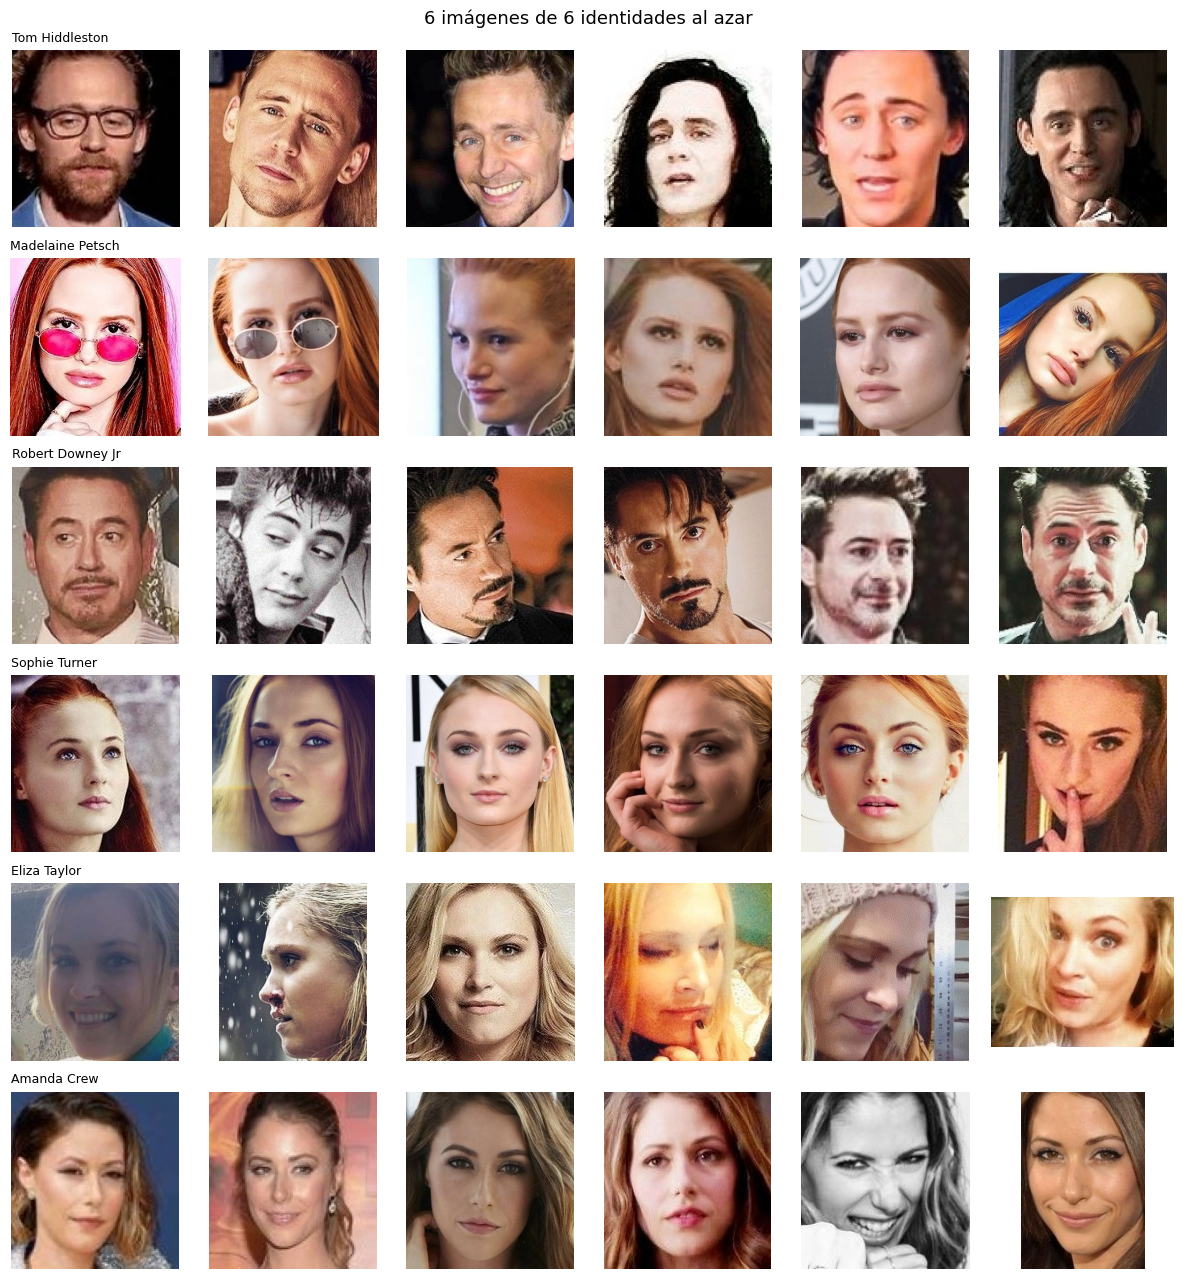

In [ ]:
rng = np.random.default_rng(42)  # semilla fija: siempre la misma muestra
identidades_muestra = rng.choice(conteo.index, 6, replace=False)

fig, axes = plt.subplots(6, 6, figsize=(12, 13))
for fila, identidad in enumerate(identidades_muestra):
    rutas = ok[ok['identidad'] == identidad]['ruta'].sample(6, random_state=42)
    for col, ruta in enumerate(rutas):
        axes[fila, col].imshow(cv2.cvtColor(cv2.imread(ruta), cv2.COLOR_BGR2RGB))
        axes[fila, col].axis('off')
    axes[fila, 0].set_title(identidad, fontsize=9, loc='left')
plt.suptitle('6 imágenes de 6 identidades al azar', fontsize=13); plt.tight_layout(); plt.show()

**Resultado:** la muestra visual confirma que las imágenes son **recortes centrados en el rostro**, con una **gran variabilidad dentro de una misma identidad**:

- **Caracterización y apariencia:** Tom Hiddleston aparece con barba y anteojos, y también caracterizado como *Loki* (pelo largo negro, piel muy pálida). Sophie Turner aparece pelirroja y rubia.
- **Edad:** Robert Downey Jr aparece joven (foto antigua en blanco y negro) y adulto.
- **Pose:** de frente, de tres cuartos y casi de perfil (Eliza Taylor, Madelaine Petsch).
- **Oclusiones:** anteojos de sol (Madelaine Petsch), manos y dedos sobre la cara (Sophie Turner, Eliza Taylor), gorro, pelo sobre el rostro.
- **Expresión:** neutra, sonrisa, gestos exagerados (Amanda Crew), ojos cerrados (Eliza Taylor).
- **Calidad e iluminación:** fotos borrosas o de baja resolución, contraluz, filtros de color y retoques típicos de Pinterest.

**Interpretación:** esta variabilidad es **positiva para el entrenamiento**, porque obliga al modelo a reconocer a la persona y no las condiciones de la foto. También es la principal fuente de **errores esperables**: las caracterizaciones fuertes, los perfiles y las oclusiones son los casos donde dos fotos de la misma persona pueden parecer de personas distintas. Estos casos se van a revisar en el análisis de errores de la notebook 2.

### 2.5 Iluminación: brillo y contraste
- **Brillo:** promedio de los píxeles en escala de grises (0 = negro, 255 = blanco).
- **Contraste:** desvío estándar de los píxeles. Un valor bajo indica una imagen "lavada" o plana.

Se analizan las distribuciones y se muestran los casos extremos, para decidir si hace falta filtrar imágenes por exposición.

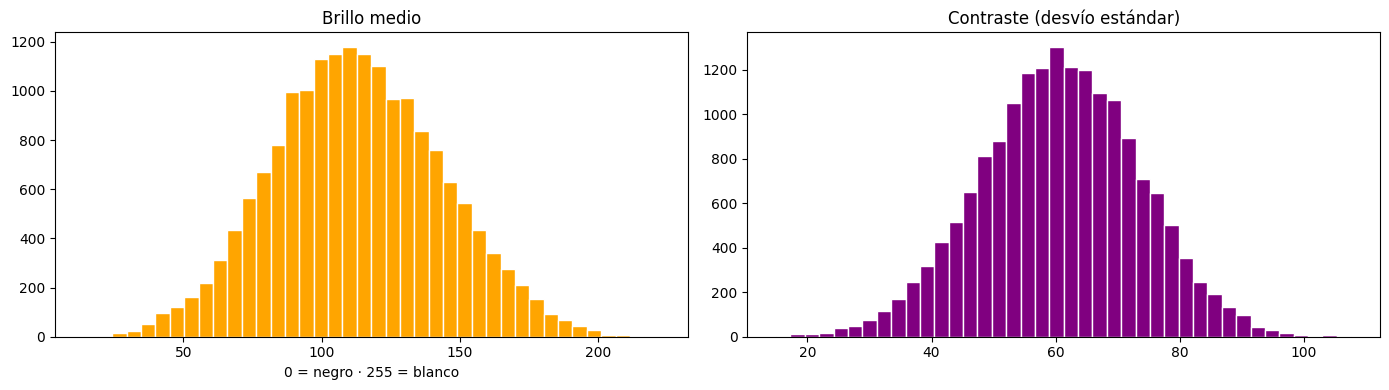

        brillo  contraste
count  17534.0    17534.0
mean     113.0       60.6
std       30.6       12.8
min       14.0       15.0
25%       91.6       52.1
50%      112.0       60.7
75%      133.9       69.4
max      221.8      107.6


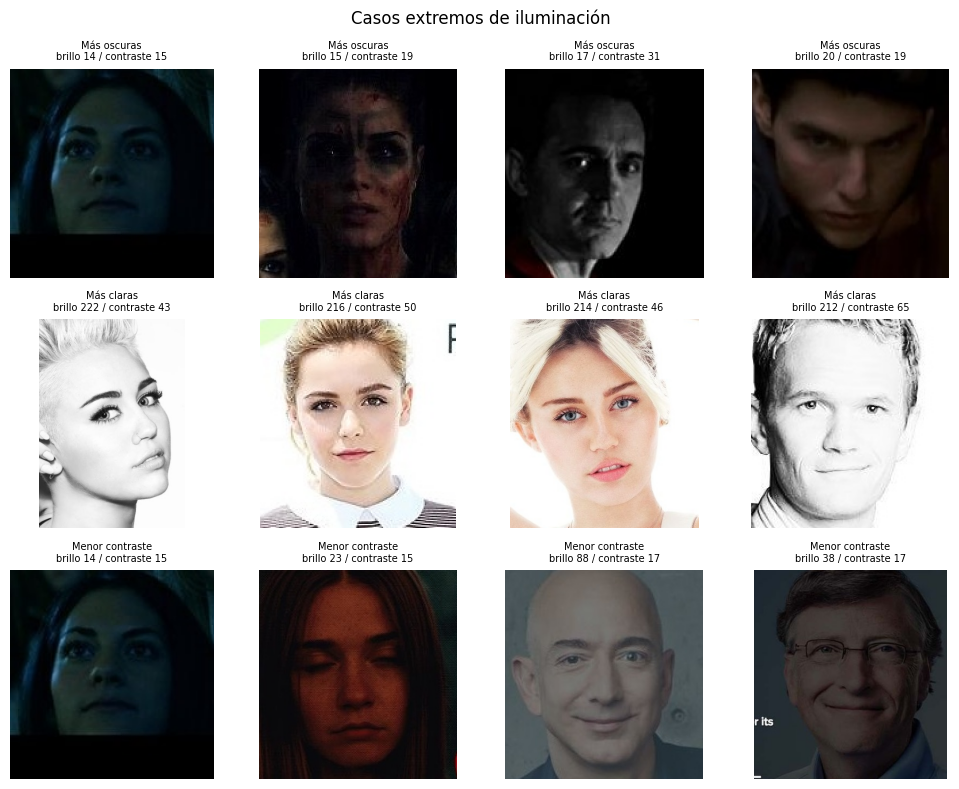

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(ok['brillo'], bins=40, color='orange', edgecolor='white'); axes[0].set_title('Brillo medio'); axes[0].set_xlabel('0 = negro · 255 = blanco')
axes[1].hist(ok['contraste'], bins=40, color='purple', edgecolor='white'); axes[1].set_title('Contraste (desvío estándar)')
plt.tight_layout(); plt.show()
print(ok[['brillo', 'contraste']].describe().round(1).to_string())

# Casos extremos: las 4 más oscuras, las 4 más claras y las 4 de menor contraste
extremos = {'Más oscuras': ok.nsmallest(4, 'brillo'), 'Más claras': ok.nlargest(4, 'brillo'), 'Menor contraste': ok.nsmallest(4, 'contraste')}
fig, axes = plt.subplots(3, 4, figsize=(10, 8))
for fila, (titulo, sub) in enumerate(extremos.items()):
    for col, (_, r) in enumerate(sub.iterrows()):
        axes[fila, col].imshow(cv2.cvtColor(cv2.imread(r['ruta']), cv2.COLOR_BGR2RGB))
        axes[fila, col].set_title(f'{titulo}\nbrillo {r["brillo"]:.0f} / contraste {r["contraste"]:.0f}', fontsize=7); axes[fila, col].axis('off')
plt.suptitle('Casos extremos de iluminación'); plt.tight_layout(); plt.show()

**Resultado:**
- **Brillo:** media de 113 (mediana 112), con una distribución aproximadamente normal y centrada. El 50% central de las imágenes está entre 92 y 134.
- **Contraste:** media de 60,6, también con forma de campana. Mínimo 15, máximo 108.

**Casos extremos:**
- **Más oscuras** (brillo de 14 a 20): escenas nocturnas o con poca luz, pero la cara sigue siendo visible.
- **Más claras** (brillo de 212 a 222): fotos sobreexpuestas o con fondo blanco y filtros de alto contraste (*high-key*). Los rasgos se distinguen.
- **Menor contraste:** imágenes "lavadas" y capturas de pantalla de videos o entrevistas, con texto superpuesto y bandas negras (Jeff Bezos, Bill Gates).

**Interpretación:** la mayoría de las imágenes tiene una exposición normal, y **aun los casos más extremos conservan el rostro reconocible**. Por eso **no se aplica un filtro agresivo por exposición**: se perderían imágenes válidas que representan condiciones reales (poca luz, contraluz). La variabilidad de iluminación se aprovecha y se refuerza en la augmentation con cambios de brillo y contraste (sección 6). Las capturas de pantalla con texto o bandas negras se controlan con las reglas de calidad de la sección 3: detección de rostro y borrosidad.

### Resumen del EDA
| Aspecto | Hallazgo | Decisión |
|---|---|---|
| Imágenes por identidad | 86 a 237 (media 167). Desbalance moderado, 2,8x | Se conservan todas las identidades. Se evalúan *class weights* o *weighted sampling* |
| Resolución | Mediana 175×185 px. 15% con algún lado < 112 px | No se descartan por tamaño de imagen. Se filtra por tamaño de cara detectada (sección 3) |
| Tipo de imagen | Rostros pre-recortados (aspecto ≈ 0,94) | Se tiene en cuenta al aplicar el detector |
| Formato | 100% `.jpg`, 0 archivos corruptos | No requiere conversión |
| Color | 7,3% en blanco y negro | Se conservan. Posible conversión a gris en la augmentation |
| Variabilidad | Pose, edad, caracterización, oclusiones, expresión | Fuente de robustez y de errores esperables |
| Iluminación | Distribución normal. Extremos aún reconocibles | Sin filtro de exposición agresivo. Brillo y contraste en la augmentation |

## 3. Control de calidad y limpieza
Se definen reglas de filtrado explícitas y reproducibles. Cada imagen se descarta en la **primera** regla que no cumple:
1. **Sin rostro:** el detector no encuentra ninguna cara.
2. **Más de un rostro:** hay una segunda cara con al menos el 50% del área de la principal, por lo que no queda claro cuál es la persona etiquetada. Si la segunda cara es mucho más chica (alguien de fondo), se conserva la cara principal.
3. **Rostro chico:** el lado menor de la caja detectada mide menos de 40 px.
4. **Borrosa:** la varianza del Laplaciano en la zona central de la cara alineada está debajo de un umbral. El Laplaciano resalta bordes; si casi no hay bordes, la imagen está desenfocada.
5. **Casi-duplicado:** dos fotos de la misma persona con similitud coseno de embeddings ArcFace mayor a 0,95. Se conserva una sola.

### 3.1 Detección, alineación y medidas de calidad
Se procesan todas las imágenes una sola vez. Para cada una se detectan los rostros con SCRFD, se elige el principal (el más grande), se alinea a 112×112 y se guardan las medidas que usan las reglas.

Como los rostros de Pins vienen muy recortados, se agrega un borde alrededor de la imagen: para detectar, un borde negro (sin él el detector no reconoce la cara, ver sección 4); para alinear, un borde que repite los píxeles del contorno, para que las caras alineadas no queden con esquinas negras.

In [ ]:
UMBRAL_CARA_MIN = 40          # px: lado mínimo del rostro detectado (sugerido por el enunciado)
RELACION_SEGUNDA_CARA = 0.5   # si la 2ª cara tiene >= 50% del área de la principal, la imagen es ambigua
FRACCION_BORDE = 0.25         # borde alrededor de la imagen: Pins tiene los rostros muy recortados

PROCESADO = f'{BASE}/procesado'
os.makedirs(PROCESADO, exist_ok=True)
ARCH_PROC, ARCH_CARAS = f'{PROCESADO}/procesamiento.pkl', f'{PROCESADO}/caras_alineadas.npy'

if os.path.exists(ARCH_PROC) and os.path.exists(ARCH_CARAS):
    # Ya se procesó en una sesión anterior: se carga desde Drive
    proc = pd.read_pickle(ARCH_PROC)
    caras_alineadas = np.load(ARCH_CARAS)
    print('Resultados cargados desde Drive (procesados en una sesión anterior).')
else:
    registros, caras_alineadas = [], []
    for ruta in tqdm(ok['ruta'], desc='Detectando y alineando'):
        img = cv2.imread(ruta)
        caras = fp.detectar(detector, img, tamanio_min_cara=0, fraccion_borde=FRACCION_BORDE)
        reg = {'ruta': ruta, 'n_caras': len(caras)}
        if caras:
            areas = [(c[2] - c[0]) * (c[3] - c[1]) for c, _, _ in caras]
            orden = np.argsort(areas)[::-1]
            caja, score, landmarks = caras[orden[0]]  # rostro principal = el más grande
            # Para alinear se extiende la imagen repitiendo sus bordes: evita esquinas negras
            m = int(FRACCION_BORDE * max(img.shape[:2]))
            img_ext = cv2.copyMakeBorder(img, m, m, m, m, cv2.BORDER_REPLICATE)
            alineada = fp.alinear(img_ext, landmarks + m)
            gris = cv2.cvtColor(alineada, cv2.COLOR_BGR2GRAY)[28:84, 28:84]  # zona central: ojos, nariz y boca
            reg.update(
                caja=caja.round(1).tolist(), landmarks=landmarks.round(1).tolist(), score_det=score,
                lado_cara=float(min(caja[2] - caja[0], caja[3] - caja[1])),
                segunda_cara=float(areas[orden[1]] / areas[orden[0]]) if len(caras) > 1 else 0.0,
                nitidez=cv2.Laplacian(gris, cv2.CV_64F).var(),  # varianza del Laplaciano: baja = borrosa
                idx_cara=len(caras_alineadas))
            caras_alineadas.append(alineada)
        registros.append(reg)

    proc = ok[['ruta', 'identidad']].merge(pd.DataFrame(registros), on='ruta')
    caras_alineadas = np.stack(caras_alineadas)  # (N, 112, 112, 3) BGR uint8
    proc.to_pickle(ARCH_PROC); np.save(ARCH_CARAS, caras_alineadas)  # se guarda para las próximas sesiones

print(f'Imágenes procesadas: {len(proc)} | con al menos un rostro: {proc["idx_cara"].notna().sum()}')
print(proc['n_caras'].value_counts().sort_index().rename('imágenes').to_string())

Detectando y alineando:   0%|          | 0/17534 [00:00<?, ?it/s]

Imágenes procesadas: 17534 | con al menos un rostro: 17528
n_caras
0        6
1    17441
2       75
3       12


El resultado se guarda en Drive (`procesado/`). Si ya existe de una sesión anterior, se carga directamente en lugar de recalcularlo.

**Resultado:** se procesaron las **17.534 imágenes** en unos 7 minutos con GPU.
- **17.528 (99,97%)** tienen al menos un rostro detectado. Solo **6** no tienen ninguno.
- **17.441 (99,5%)** tienen exactamente un rostro.
- **87** tienen más de un rostro (75 con dos y 12 con tres). En la regla 2 se decide cuáles se conservan: si la cara secundaria es mucho más chica que la principal (alguien de fondo), la imagen se conserva con su rostro principal.

**Interpretación:** gracias al borde agregado, el detector funciona en prácticamente todo el dataset, aun siendo recortes muy ajustados. Los casos sin rostro o con varios rostros son muy pocos.

### 3.2 Elección del umbral de nitidez
El valor de la varianza del Laplaciano depende del tipo de imagen, por lo que el umbral se elige mirando la distribución y las caras menos nítidas, y no con un valor genérico.

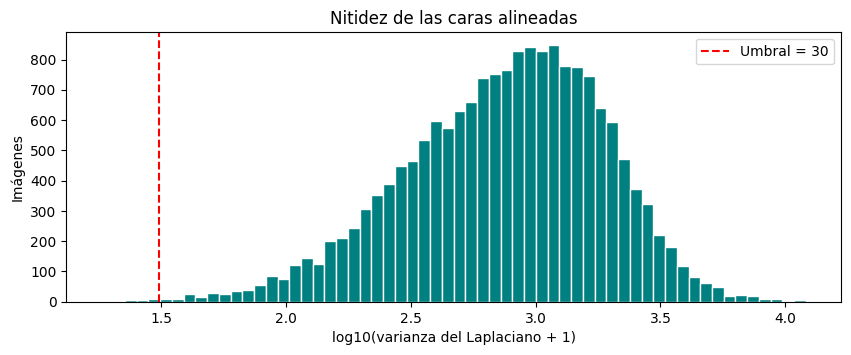

count    17528.0
mean      1081.5
std        985.8
min         17.2
25%        405.7
50%        814.8
75%       1451.9
max      12118.0


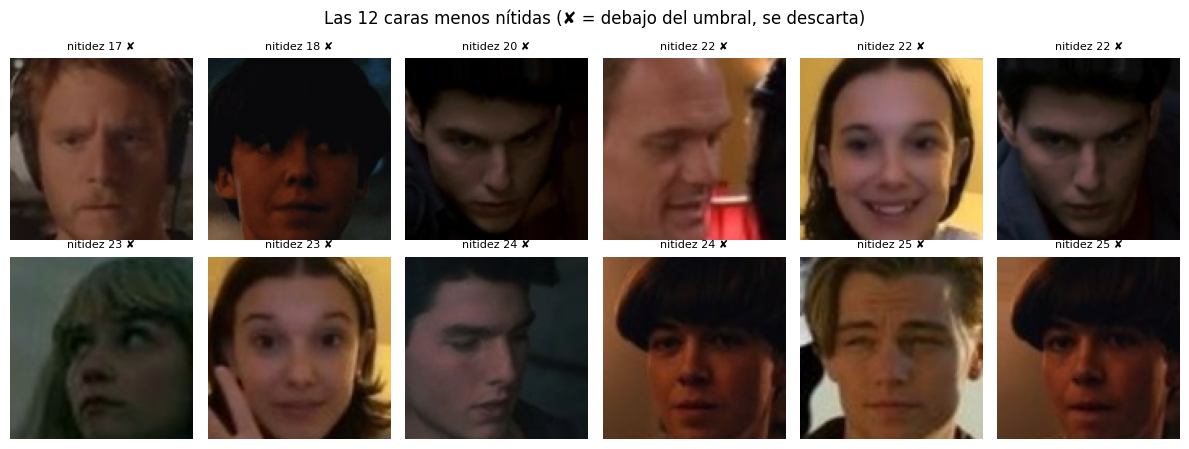

Debajo del umbral (30): 24 imágenes


In [ ]:
UMBRAL_NITIDEZ = 30  # varianza del Laplaciano en la zona central de la cara alineada

con_cara = proc[proc['idx_cara'].notna()]
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.hist(np.log10(con_cara['nitidez'] + 1), bins=60, color='teal', edgecolor='white')
ax.axvline(np.log10(UMBRAL_NITIDEZ + 1), color='red', ls='--', label=f'Umbral = {UMBRAL_NITIDEZ}')
ax.set_xlabel('log10(varianza del Laplaciano + 1)'); ax.set_ylabel('Imágenes'); ax.legend()
ax.set_title('Nitidez de las caras alineadas'); plt.show()
print(con_cara['nitidez'].describe().round(1).to_string())

# Las 12 caras menos nítidas, ordenadas: permiten validar visualmente dónde poner el umbral
menos_nitidas = con_cara.nsmallest(12, 'nitidez')
fig, axes = plt.subplots(2, 6, figsize=(12, 4.6))
for ax, (_, r) in zip(axes.flat, menos_nitidas.iterrows()):
    ax.imshow(cv2.cvtColor(caras_alineadas[int(r['idx_cara'])], cv2.COLOR_BGR2RGB)); ax.axis('off')
    ax.set_title(f'nitidez {r["nitidez"]:.0f}' + (' ✘' if r['nitidez'] < UMBRAL_NITIDEZ else ''), fontsize=8)
plt.suptitle('Las 12 caras menos nítidas (✘ = debajo del umbral, se descarta)'); plt.tight_layout(); plt.show()
print(f'Debajo del umbral ({UMBRAL_NITIDEZ}): {(con_cara["nitidez"] < UMBRAL_NITIDEZ).sum()} imágenes')

**Resultado:** la nitidez sigue una distribución aproximadamente log-normal, con **mediana de 815** y mínimo de 17. Las caras menos nítidas (de 17 a 25) son cuadros de video con poca luz y desenfoque leve: todavía se reconocen, pero tienen poco detalle.

**Decisión:** se fija **`UMBRAL_NITIDEZ = 30`**, unas 27 veces menor que la mediana. Es un umbral **conservador**: elimina solo la cola extrema de imágenes muy blandas. Un umbral más alto descartaría también fotos simplemente oscuras pero válidas, porque con poca luz la imagen tiene menos bordes. Esas fotos se decidió conservar en el EDA, ya que representan condiciones reales de uso.

### 3.3 Embeddings ArcFace
Se calculan los embeddings ArcFace (512 dimensiones) de todas las caras alineadas. Se usan para detectar casi-duplicados (regla 5) y para el clustering exploratorio (sección 5). También se guardan en Drive.

In [ ]:
ARCH_EMB = f'{PROCESADO}/embeddings_arcface.npy'
if os.path.exists(ARCH_EMB):
    emb_todas = np.load(ARCH_EMB)
    print('Embeddings cargados desde Drive.')
else:
    emb_todas = embeddings_arcface(list(caras_alineadas))  # (N, 512) normalizados L2, en GPU
    np.save(ARCH_EMB, emb_todas)
print(f'Embeddings: {emb_todas.shape}')

Embeddings: (17528, 512)


### 3.4 Aplicación de las reglas de calidad
Cada imagen se cuenta en la **primera** regla que no cumple. Para los casi-duplicados se compara cada par de fotos de una misma persona: si la similitud coseno supera 0,95, son prácticamente la misma foto (recortada, espejada o recomprimida), y se conserva solo la primera.

In [ ]:
UMBRAL_DUPLICADO = 0.95  # similitud coseno entre dos fotos de la misma persona

def motivo_descarte(r):
    # Cada imagen se cuenta en la PRIMERA regla que no cumple
    if r['n_caras'] == 0:                          return '1. sin rostro'
    if r['segunda_cara'] >= RELACION_SEGUNDA_CARA: return '2. más de un rostro'
    if r['lado_cara'] < UMBRAL_CARA_MIN:           return '3. rostro chico'
    if r['nitidez'] < UMBRAL_NITIDEZ:              return '4. borrosa'
    return None

proc['descarte'] = proc.apply(motivo_descarte, axis=1)

# Regla 5: casi-duplicados dentro de cada identidad (se conserva la primera de cada grupo)
proc['duplicado_de'] = None
for identidad, grupo in proc[proc['descarte'].isna()].groupby('identidad'):
    idx = grupo['idx_cara'].astype(int).to_numpy()
    sim = emb_todas[idx] @ emb_todas[idx].T  # similitud coseno entre todas las fotos de la persona
    eliminadas = set()
    for i in range(len(idx)):
        if i in eliminadas: continue
        for j in np.where(sim[i, i + 1:] > UMBRAL_DUPLICADO)[0] + i + 1:
            if j not in eliminadas:
                eliminadas.add(j)
                proc.loc[grupo.index[j], ['descarte', 'duplicado_de']] = ['5. casi-duplicado', grupo['ruta'].iloc[i]]

resumen = proc['descarte'].fillna('✔ se conserva').value_counts().sort_index()
resumen = pd.DataFrame({'imágenes': resumen, '%': (100 * resumen / len(proc)).round(2)})
print(resumen.to_string())
curadas = proc[proc['descarte'].isna()].reset_index(drop=True)
print(f'\nImágenes curadas: {len(curadas)} de {len(proc)} | identidades: {curadas["identidad"].nunique()}')
print(f'Imágenes por identidad tras la limpieza: mín {curadas.groupby("identidad").size().min()}, '
      f'media {curadas.groupby("identidad").size().mean():.0f}')

                     imágenes      %
descarte                            
1. sin rostro               6   0.03
2. más de un rostro         1   0.01
4. borrosa                 24   0.14
5. casi-duplicado         609   3.47
✔ se conserva           16894  96.35

Imágenes curadas: 16894 de 17534 | identidades: 105
Imágenes por identidad tras la limpieza: mín 86, media 161


**Resultado:**
| Regla | Descartadas | % |
|---|---|---|
| 1. Sin rostro | 6 | 0,03% |
| 2. Más de un rostro (ambiguo) | 1 | 0,01% |
| 3. Rostro chico (< 40 px) | 0 | 0% |
| 4. Borrosa (nitidez < 30) | 24 | 0,14% |
| 5. Casi-duplicado (similitud > 0,95) | 609 | 3,47% |
| **Se conservan** | **16.894** | **96,35%** |

**Interpretación:**
- **Ningún rostro es menor a 40 px**, algo esperable porque el EDA mostró que la imagen más chica mide 80 px y la cara ocupa casi toda la imagen.
- De las 87 imágenes con más de un rostro, **solo 1 resultó ambigua**. En las demás, la cara secundaria es mucho más chica (alguien de fondo) y se conserva la principal.
- La regla más importante son los **casi-duplicados (609)**: Pins se armó descargando imágenes de Pinterest, donde la misma foto aparece varias veces recortada o recomprimida. Eliminarlos es importante para que **la misma foto no termine en train y en test a la vez**, lo que sería una fuga de datos e inflaría las métricas.
- Después de la limpieza se conservan las **105 identidades**, con un mínimo de 86 y una media de 161 imágenes por persona: el dataset sigue siendo suficiente para entrenar.

### 3.5 Ejemplos de imágenes descartadas por cada regla
Se muestran ejemplos de cada regla para validar que los umbrales elegidos tienen sentido. En los casi-duplicados se muestra la foto conservada al lado de la descartada.

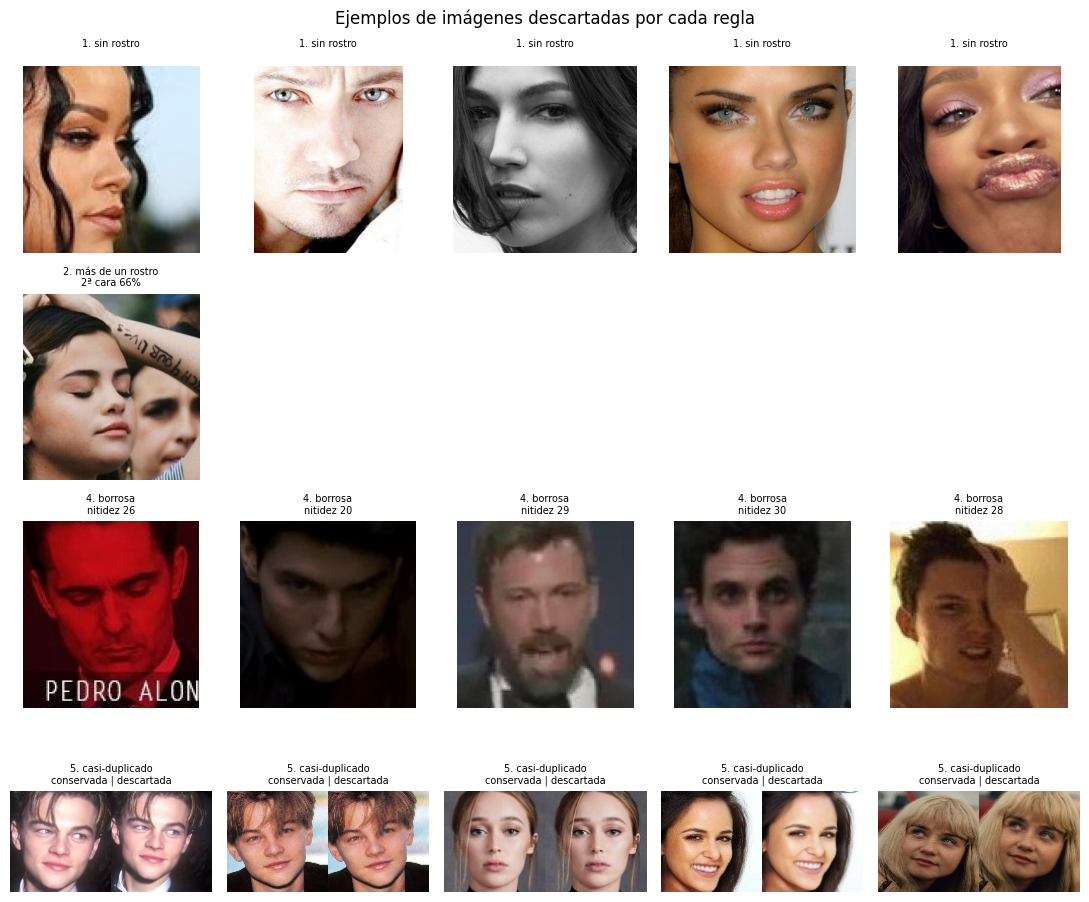

In [ ]:
def mostrar(ax, ruta, titulo):
    ax.imshow(cv2.cvtColor(cv2.imread(ruta), cv2.COLOR_BGR2RGB)); ax.set_title(titulo, fontsize=7); ax.axis('off')

reglas = sorted(proc['descarte'].dropna().unique())
fig, axes = plt.subplots(len(reglas), 5, figsize=(11, 2.4 * len(reglas)), squeeze=False)
for fila, regla in enumerate(reglas):
    sub = proc[proc['descarte'] == regla].sample(min(5, (proc['descarte'] == regla).sum()), random_state=1)
    for col in range(5):
        axes[fila, col].axis('off')
        if col >= len(sub): continue
        r = sub.iloc[col]
        if regla.startswith('5'):  # duplicado: conservada | descartada
            par = np.hstack([cv2.resize(cv2.imread(r['duplicado_de']), (100, 100)), cv2.resize(cv2.imread(r['ruta']), (100, 100))])
            axes[fila, col].imshow(cv2.cvtColor(par, cv2.COLOR_BGR2RGB)); axes[fila, col].set_title(f'{regla}\nconservada | descartada', fontsize=7)
        else:
            extra = {'2': f'2ª cara {r["segunda_cara"]:.0%}', '3': f'lado {r["lado_cara"]:.0f}px', '4': f'nitidez {r["nitidez"]:.0f}'}.get(regla[0], '')
            mostrar(axes[fila, col], r['ruta'], f'{regla}\n{extra}')
plt.suptitle('Ejemplos de imágenes descartadas por cada regla'); plt.tight_layout(); plt.show()

**Validación visual de las reglas:**
- **1. Sin rostro:** en realidad estas imágenes sí contienen una cara, pero son **primeros planos extremos** donde el rostro está cortado (falta la frente, el mentón o media cara). El detector no las reconoce porque no ve el rostro completo, y sin landmarks confiables no se pueden alinear. Descartarlas es razonable: son solo 6 imágenes (0,03%) y no podrían alinearse igual que el resto.
- **2. Más de un rostro:** el único caso ambiguo tiene una segunda persona que ocupa el 66% del área de la principal. No hay forma automática de saber cuál es la persona etiquetada, así que la regla funciona como se esperaba.
- **4. Borrosa:** son imágenes desenfocadas y con poca luz, algunas con texto superpuesto (capturas de video). El umbral de 30 captura casos claramente pobres en detalle.
- **5. Casi-duplicado:** los pares conservada/descartada son **la misma foto** con distinto recorte, tamaño o compresión. Esto confirma que el umbral de 0,95 detecta duplicados reales y no fotos distintas de la misma persona.

## 4. Detección y alineación
**Detector elegido: SCRFD** (`det_10g.onnx`, paquete `buffalo_l` de InsightFace).
- Es preciso y rápido: se procesaron 17.534 imágenes en unos 7 minutos con GPU.
- Devuelve los **5 landmarks** (ojos, nariz y comisuras de la boca) que se necesitan para alinear.
- Es el detector con el que se entrenó ArcFace, así que la alineación queda consistente con el modelo preentrenado.
- Frente a MTCNN (visto en clase), es más moderno y robusto a pose y oclusiones.

**Alineación:** con los 5 landmarks se calcula una transformación de similitud (rotación, escala y traslación) que lleva esos puntos a posiciones fijas de una plantilla de referencia (`norm_crop`), y se recorta a **112×112**. Así, en todas las caras los ojos, la nariz y la boca quedan en el mismo lugar.

Este mismo pipeline (`face_pipeline.py`) es el que usa la app.

### 4.1 Efecto del borde agregado
Se compara la tasa de detección en una muestra de 300 imágenes, con y sin borde alrededor de la imagen.

In [ ]:
muestra = ok.sample(300, random_state=42)['ruta']
sin_borde = np.mean([len(fp.detectar(detector, cv2.imread(r), tamanio_min_cara=0)) > 0 for r in muestra])
con_borde = np.mean([len(fp.detectar(detector, cv2.imread(r), tamanio_min_cara=0, fraccion_borde=FRACCION_BORDE)) > 0 for r in muestra])
print(f'Imágenes con al menos un rostro detectado (muestra de {len(muestra)}):')
print(f'  sin borde:               {sin_borde:.1%}')
print(f'  con borde del {FRACCION_BORDE:.0%}:        {con_borde:.1%}')

Imágenes con al menos un rostro detectado (muestra de 300):
  sin borde:               10.3%
  con borde del 25%:        100.0%


**Resultado:** sobre una muestra de 300 imágenes:
- **Sin borde:** se detecta un rostro en el **10,3%**.
- **Con un borde del 25%:** se detecta en el **100%**.

**Interpretación:** SCRFD fue entrenado con fotos donde la cara forma parte de una escena (con fondo y contexto alrededor). En Pins, la cara ocupa toda la imagen y toca los bordes, por lo que el detector no la reconoce como tal. Agregar un borde "aleja" la cara y le devuelve el contexto que espera.

**Importante para la app:** las fotos que se suben a la app son fotos normales (personas en una escena), por lo que **en la app no se agrega borde**. Lo que sí es idéntico en la notebook y en la app es la alineación (`norm_crop` a 112×112) y la normalización de píxeles, que es lo que define la entrada al modelo.

### 4.2 Antes / después de la alineación
Arriba: imagen original con la caja detectada y los 5 landmarks (rojo: ojos, amarillo: nariz, celeste: comisuras). Abajo: la cara alineada a 112×112.

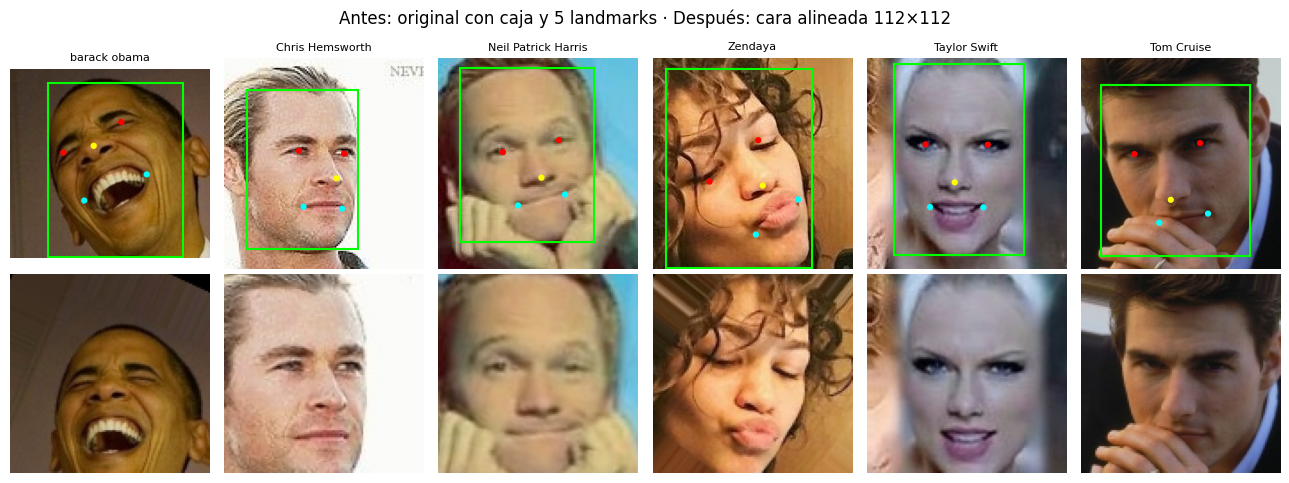

In [ ]:
ejemplos = curadas.sample(6, random_state=7)
fig, axes = plt.subplots(2, 6, figsize=(13, 5))
for col, (_, r) in enumerate(ejemplos.iterrows()):
    img = cv2.cvtColor(cv2.imread(r['ruta']), cv2.COLOR_BGR2RGB)
    x1, y1, x2, y2 = r['caja']
    axes[0, col].imshow(img); axes[0, col].add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color='lime', lw=1.5))
    lm = np.array(r['landmarks']); axes[0, col].scatter(lm[:, 0], lm[:, 1], c=['red', 'red', 'yellow', 'cyan', 'cyan'], s=12)
    axes[0, col].set_title(r['identidad'], fontsize=8); axes[0, col].axis('off')
    axes[1, col].imshow(cv2.cvtColor(caras_alineadas[int(r['idx_cara'])], cv2.COLOR_BGR2RGB)); axes[1, col].axis('off')
plt.suptitle('Antes: original con caja y 5 landmarks · Después: cara alineada 112×112'); plt.tight_layout(); plt.show()

### 4.3 Guardado del dataset curado
Se guarda la tabla de imágenes curadas para usarla en las secciones siguientes y en la notebook 2.

In [ ]:
curadas.to_pickle(f'{PROCESADO}/curadas.pkl')
proc.to_pickle(ARCH_PROC)  # actualiza la tabla con el motivo de descarte de cada imagen
print('Guardado en', PROCESADO, '→', sorted(os.listdir(PROCESADO)))

Guardado en /content/drive/MyDrive/TP_FaceRec/procesado → ['caras_alineadas.npy', 'curadas.pkl', 'embeddings_arcface.npy', 'procesamiento.pkl']


## 5. Clustering exploratorio
Se usa clustering como herramienta de **análisis del dataset**: si los embeddings de una misma persona se agrupan, las etiquetas son consistentes; las imágenes que quedan lejos de su grupo pueden ser errores de etiquetado u *outliers*.

Se usan los embeddings ArcFace (512 dimensiones) de las imágenes curadas.

### 5.1 Proyección t-SNE
t-SNE reduce los 512 números de cada embedding a 2 para poder graficarlos, tratando de mantener cerca lo que estaba cerca. Se grafican 15 identidades elegidas al azar (con todas son demasiados colores para distinguir). Las imágenes en blanco y negro se marcan con una ×, para ver si forman sub-grupos.

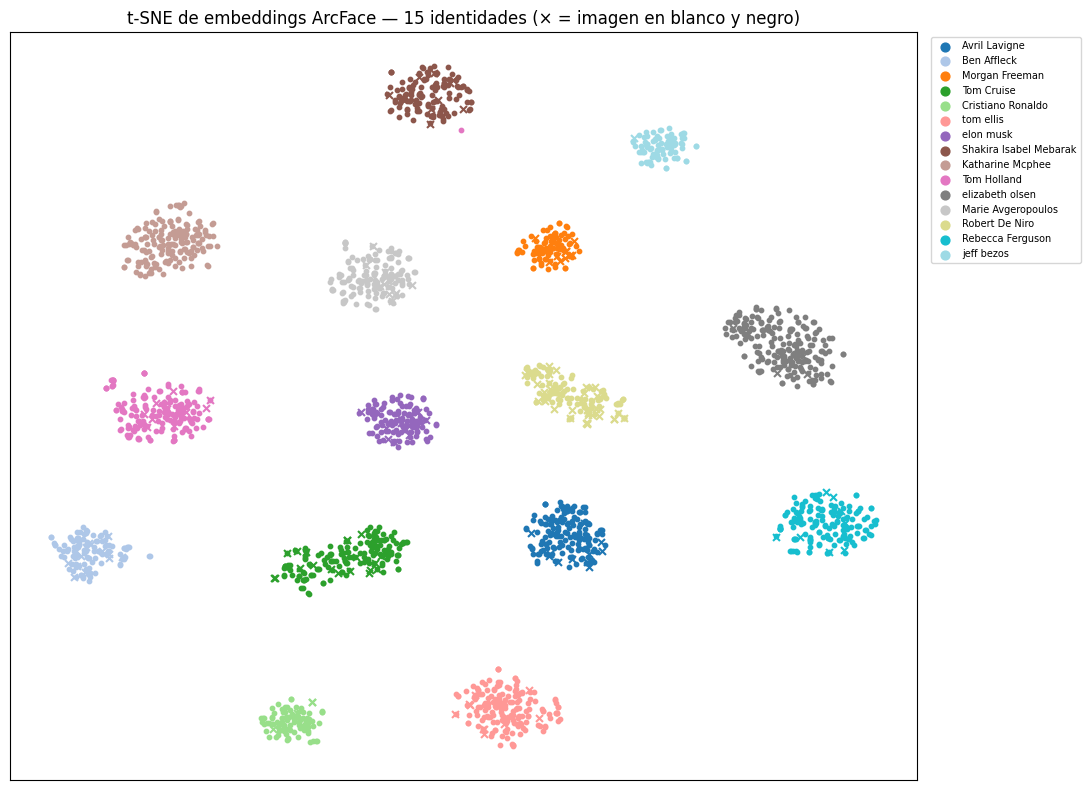

In [ ]:
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score

emb_cur = emb_todas[curadas['idx_cara'].astype(int).to_numpy()]  # embeddings de las imágenes curadas
etiquetas = curadas['identidad'].to_numpy()
es_gris = curadas['ruta'].map(ok.set_index('ruta')['es_gris']).to_numpy().astype(bool)

rng = np.random.default_rng(42)
ids_tsne = rng.choice(np.unique(etiquetas), 15, replace=False)
m = np.isin(etiquetas, ids_tsne)
emb_2d = TSNE(n_components=2, metric='cosine', perplexity=30, random_state=42).fit_transform(emb_cur[m])

fig, ax = plt.subplots(figsize=(11, 8))
colores = plt.cm.tab20(np.linspace(0, 1, len(ids_tsne)))
for c, ident in zip(colores, ids_tsne):
    sel = etiquetas[m] == ident
    ax.scatter(emb_2d[sel & ~es_gris[m], 0], emb_2d[sel & ~es_gris[m], 1], s=10, color=c, label=ident)
    ax.scatter(emb_2d[sel & es_gris[m], 0], emb_2d[sel & es_gris[m], 1], s=25, color=c, marker='x')
ax.legend(fontsize=7, markerscale=2, bbox_to_anchor=(1.01, 1), loc='upper left')
ax.set_title('t-SNE de embeddings ArcFace — 15 identidades (× = imagen en blanco y negro)'); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

**Resultado:** las 15 identidades forman **grupos compactos y bien separados entre sí**. ArcFace genera embeddings donde las fotos de una misma persona quedan juntas y las de personas distintas quedan lejos, aun sin haber sido entrenado con este dataset.

**Observaciones:**
- **Imágenes en blanco y negro (×):** aparecen **mezcladas dentro del grupo de su propia persona**, no forman sub-grupos aparte. El modelo reconoce a la persona independientemente del color, y esto confirma la decisión de conservarlas.
- **Grupos alargados o con dos lóbulos** (Robert De Niro, Tom Cruise): corresponden a identidades fotografiadas en **edades muy distintas** (fotos de juventud y de adultez). Son sub-grupos por condiciones de captura dentro de la misma persona.
- Se ve algún **punto aislado lejos de su grupo** (por ejemplo, un punto rosa de Tom Holland cerca del grupo de Shakira). Son candidatos a outliers o errores de etiquetado, y se analizan en 5.3.

### 5.2 K-Means y comparación con las identidades reales
Se agrupan los embeddings con K-Means usando k = 105 (una por identidad), **sin darle las etiquetas**, y se compara el resultado con las identidades reales:
- **ARI** (Adjusted Rand Index): qué tanto coinciden los grupos encontrados con las identidades. 1 = coincidencia perfecta, 0 = como al azar.
- **NMI** (Normalized Mutual Information): cuánta información comparten los grupos y las identidades. 1 = perfecto.
- **Silhouette**: qué tan cerca está cada punto de su grupo comparado con el grupo vecino. Va de -1 a 1; cuanto más alto, más separados están los grupos.
- **Pureza por identidad**: qué porcentaje de las fotos de cada persona cae en un mismo cluster.

In [ ]:
k = len(np.unique(etiquetas))
kmeans = KMeans(n_clusters=k, n_init=5, random_state=42).fit(emb_cur)
ari = adjusted_rand_score(etiquetas, kmeans.labels_)
nmi = normalized_mutual_info_score(etiquetas, kmeans.labels_)
idx_s = rng.choice(len(emb_cur), 5000, replace=False)  # silhouette sobre una muestra (es costoso)
sil_real = silhouette_score(emb_cur[idx_s], etiquetas[idx_s], metric='cosine')
sil_km = silhouette_score(emb_cur[idx_s], kmeans.labels_[idx_s], metric='cosine')
print(f'K-Means con k = {k} clusters')
print(f'  ARI (acuerdo clusters vs. identidades, 1 = perfecto): {ari:.3f}')
print(f'  NMI (información compartida, 1 = perfecto):          {nmi:.3f}')
print(f'  Silhouette usando las identidades reales:             {sil_real:.3f}')
print(f'  Silhouette usando los clusters de K-Means:            {sil_km:.3f}')

# Pureza por identidad: qué fracción de sus fotos cae en su cluster mayoritario
tabla = pd.crosstab(pd.Series(etiquetas, name='identidad'), kmeans.labels_)
pureza = (tabla.max(axis=1) / tabla.sum(axis=1)).sort_values()
print(f'\nPureza media por identidad: {pureza.mean():.1%}')
print('Identidades más repartidas entre clusters:\n', (pureza.head(5) * 100).round(1).astype(str).add('%').to_string())

K-Means con k = 105 clusters
  ARI (acuerdo clusters vs. identidades, 1 = perfecto): 0.974
  NMI (información compartida, 1 = perfecto):          0.994
  Silhouette usando las identidades reales:             0.482
  Silhouette usando los clusters de K-Means:            0.459

Pureza media por identidad: 99.1%
Identidades más repartidas entre clusters:
 identidad
Alex Lawther    53.6%
amber heard     65.9%
Rihanna         95.3%
Zendaya         98.5%
Ben Affleck     99.2%


**Resultado:**
| Métrica | Valor |
|---|---|
| ARI | **0,974** |
| NMI | **0,994** |
| Silhouette (identidades reales) | 0,482 |
| Silhouette (clusters K-Means) | 0,459 |
| Pureza media por identidad | **99,1%** |

**Interpretación:**
- Sin darle ninguna etiqueta, K-Means **recupera casi exactamente las 105 identidades** (ARI 0,974, NMI 0,994). Esto indica que el dataset está **bien etiquetado en su gran mayoría** y que los embeddings ArcFace separan muy bien a las personas.
- La **silhouette de 0,48** es positiva y moderada. No es cercana a 1 porque, en un espacio de 512 dimensiones con 105 grupos, la distancia entre grupos vecinos no es tan grande comparada con la variación dentro de cada persona (pose, edad, iluminación). Que sea parecida usando las etiquetas reales (0,48) y los clusters de K-Means (0,46) confirma que los grupos naturales de los datos coinciden con las identidades.
- **Excepciones:** casi todas las identidades tienen una pureza superior al 95%, salvo **Alex Lawther (53,6%)** y **Amber Heard (65,9%)**, cuyas fotos quedaron repartidas en dos clusters. Hay dos explicaciones posibles: K-Means separó a la persona en dos sub-grupos por apariencia (por ejemplo, edad o caracterización), o la carpeta contiene fotos de otra persona mal etiquetadas. Esto se revisa en 5.3.

### 5.3 Outliers y posibles etiquetas erróneas
Para cada identidad se calcula su **centroide** (el embedding promedio de todas sus fotos, que representa a la persona "típica"). Luego, para cada foto se mide su similitud con el centroide de su propia identidad y con el de la identidad más parecida.

**Regla:** si una foto se parece **más al centroide de otra persona que al de la suya**, se considera una posible etiqueta errónea.

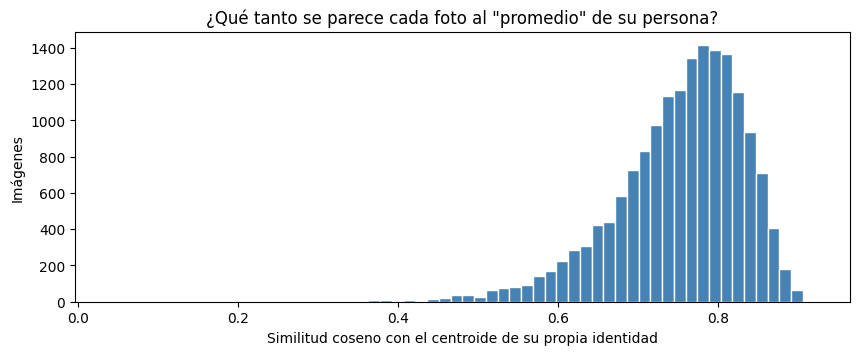

Fotos más parecidas al centroide de OTRA identidad: 6 (0.04%)


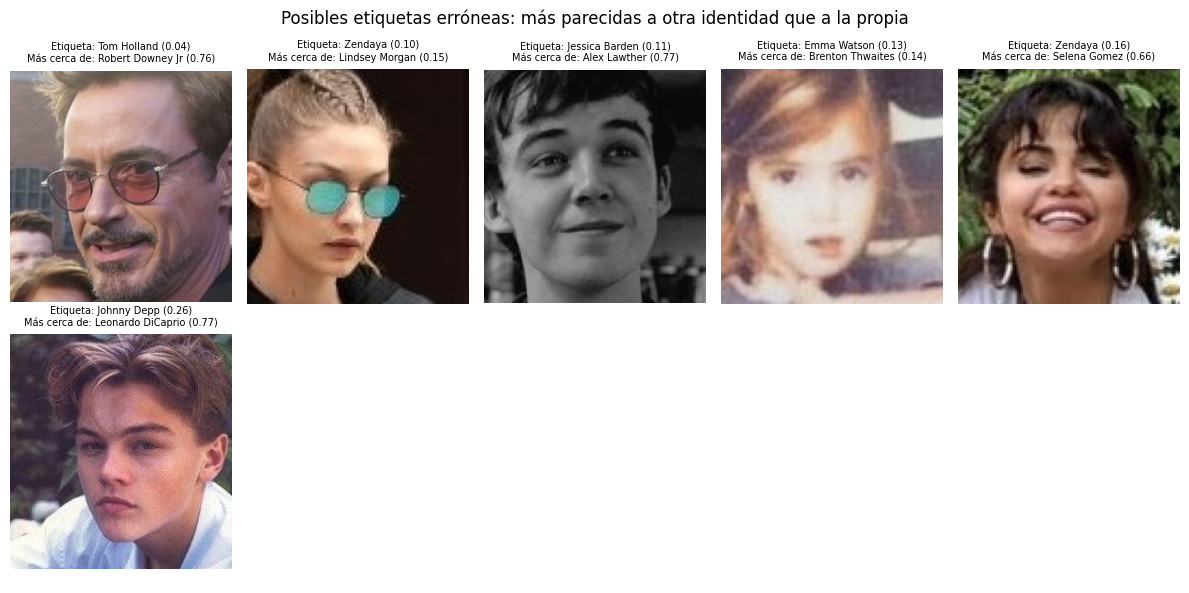

In [ ]:
centroides = pd.DataFrame(emb_cur).groupby(etiquetas).mean()
nombres_c = centroides.index.to_numpy()
C = centroides.to_numpy().copy(); C /= np.linalg.norm(C, axis=1, keepdims=True)  # centroides normalizados
sim_c = emb_cur @ C.T  # similitud de cada foto con cada centroide
pos_propia = np.searchsorted(nombres_c, etiquetas)
propio = sim_c[np.arange(len(emb_cur)), pos_propia]
sim_c_otro = sim_c.copy(); sim_c_otro[np.arange(len(emb_cur)), pos_propia] = -1
mejor_otro, nombre_otro = sim_c_otro.max(axis=1), nombres_c[sim_c_otro.argmax(axis=1)]

curadas['sim_propia'], curadas['sim_otra'], curadas['ident_mas_cercana'] = propio, mejor_otro, nombre_otro
curadas['mal_etiquetada'] = curadas['sim_otra'] > curadas['sim_propia']  # se parece más a OTRA persona

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.hist(curadas['sim_propia'], bins=60, color='steelblue', edgecolor='white')
ax.set_xlabel('Similitud coseno con el centroide de su propia identidad'); ax.set_ylabel('Imágenes')
ax.set_title('¿Qué tanto se parece cada foto al "promedio" de su persona?'); plt.show()
print(f'Fotos más parecidas al centroide de OTRA identidad: {curadas["mal_etiquetada"].sum()} '
      f'({curadas["mal_etiquetada"].mean():.2%})')

sospechosas = curadas[curadas['mal_etiquetada']].nsmallest(10, 'sim_propia')
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
for ax, (_, r) in zip(axes.flat, sospechosas.iterrows()):
    ax.imshow(cv2.cvtColor(cv2.imread(r['ruta']), cv2.COLOR_BGR2RGB)); ax.axis('off')
    ax.set_title(f'Etiqueta: {r["identidad"]} ({r["sim_propia"]:.2f})\nMás cerca de: {r["ident_mas_cercana"]} ({r["sim_otra"]:.2f})', fontsize=7)
for ax in axes.flat[len(sospechosas):]: ax.axis('off')
plt.suptitle('Posibles etiquetas erróneas: más parecidas a otra identidad que a la propia'); plt.tight_layout(); plt.show()

**Resultado:** la similitud de cada foto con el centroide de su identidad se concentra entre 0,7 y 0,85, con una cola larga hacia valores bajos. Solo **6 imágenes (0,04%)** se parecen más a otra identidad que a la propia:

| Etiqueta | Similitud propia | Identidad más cercana | Interpretación |
|---|---|---|---|
| Tom Holland | 0,04 | Robert Downey Jr (0,76) | Error de etiqueta: es otra persona del dataset |
| Jessica Barden | 0,11 | Alex Lawther (0,77) | Error de etiqueta: es otra persona del dataset |
| Johnny Depp | 0,26 | Leonardo DiCaprio (0,77) | Error de etiqueta: es otra persona del dataset |
| Zendaya | 0,16 | Selena Gomez (0,66) | Error de etiqueta: es otra persona del dataset |
| Zendaya | 0,10 | Lindsey Morgan (0,15) | Persona ajena al dataset (no se parece a nadie) |
| Emma Watson | 0,13 | Brenton Thwaites (0,14) | Foto de la infancia: la variación de edad es extrema |

**Interpretación:**
- Los errores siguen un **patrón**: en varios casos la persona confundida es alguien que suele **aparecer junto a la etiquetada** (compañeros de elenco). Esto es típico de un dataset armado descargando imágenes por nombre desde Pinterest: al buscar a una persona también aparecen fotos de quienes la acompañan.
- Cuando la similitud con la otra identidad es alta (0,66 a 0,77), la foto es claramente de esa otra persona. Cuando ambas similitudes son bajas (0,10 a 0,16), es alguien que no está en el dataset o una foto atípica (como la de la infancia).
- La cantidad es muy baja (0,04%), lo que es coherente con el ARI de 0,974: el dataset está mayormente bien etiquetado.

### 5.3 b) Identidades repartidas en dos clusters
Alex Lawther y Amber Heard tienen una pureza baja en K-Means: sus fotos quedaron repartidas en dos clusters. Se muestran 8 fotos de cada uno de sus dos clusters principales para ver si se trata de la misma persona con distinta apariencia o si hay fotos de otra persona.

/tmp/ipykernel_638/2760999741.py:14: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.suptitle(f'{ident}: sus dos clusters principales'); plt.tight_layout(); plt.show()


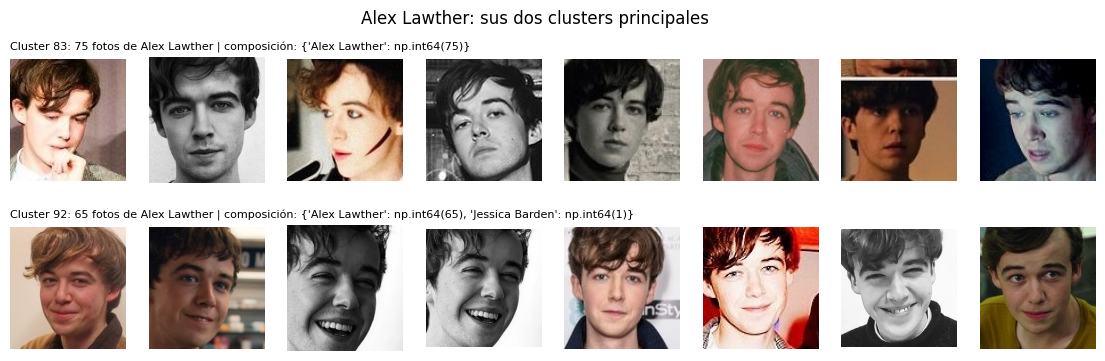

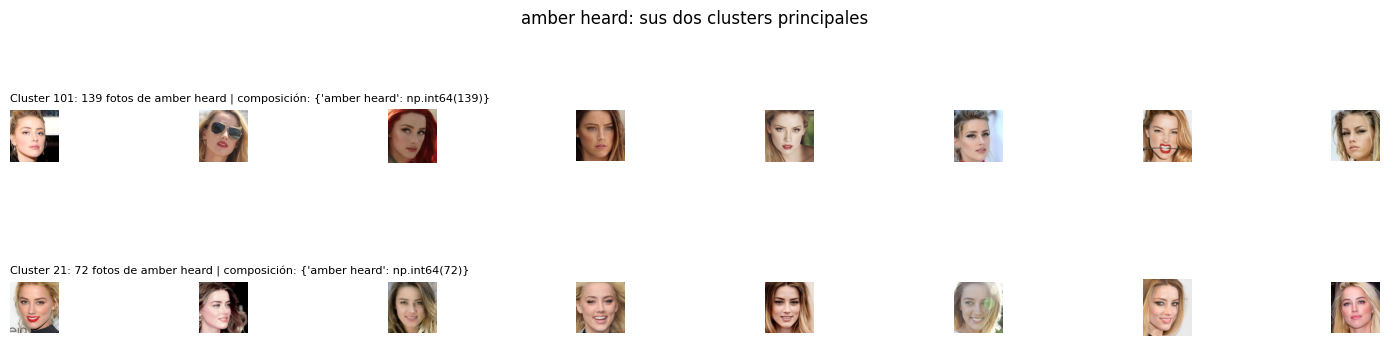

In [ ]:
for ident in ['Alex Lawther', 'amber heard']:
    sel = np.where(etiquetas == ident)[0]
    clusters, cant = np.unique(kmeans.labels_[sel], return_counts=True)
    principales = clusters[np.argsort(cant)[::-1][:2]]
    fig, axes = plt.subplots(2, 8, figsize=(14, 4))
    for fila, cl in enumerate(principales):
        fotos = sel[kmeans.labels_[sel] == cl]
        # ¿Con quién comparte este cluster? (otras identidades dentro del mismo cluster)
        otros = pd.Series(etiquetas[kmeans.labels_ == cl]).value_counts()
        for col, i in enumerate(rng.choice(fotos, min(8, len(fotos)), replace=False)):
            axes[fila, col].imshow(cv2.cvtColor(cv2.imread(curadas['ruta'].iloc[i]), cv2.COLOR_BGR2RGB)); axes[fila, col].axis('off')
        for ax in axes[fila, min(8, len(fotos)):]: ax.axis('off')
        axes[fila, 0].set_title(f'Cluster {cl}: {len(fotos)} fotos de {ident} | composición: {dict(otros.head(3))}', fontsize=8, loc='left')
    plt.suptitle(f'{ident}: sus dos clusters principales'); plt.tight_layout(); plt.show()

**Resultado (Amber Heard):** sus dos clusters principales (139 y 72 fotos) están formados **únicamente por fotos etiquetadas como Amber Heard**, sin mezcla con otras identidades. Visualmente son consistentes con la misma persona: un cluster agrupa fotos más variadas (anteojos de sol, pelo rojo, perfiles) y el otro fotos frontales, sonriendo y con pelo rubio.

**Conclusión de 5.3 b:** en ambos casos la pureza baja se debe a **variabilidad de apariencia dentro de la identidad** (expresión, iluminación, peinado), y no a errores de etiquetado. Por lo tanto **no se descarta ninguno de estos clusters**; solo se descartan las 6 imágenes detectadas en 5.3.

### 5.4 Descarte de posibles etiquetas erróneas
Las imágenes que se parecen más a otra identidad que a la propia se **descartan** en lugar de corregirse. Con más de 16.000 imágenes, revisarlas una por una a mano no es viable, y su cantidad es baja frente al total. Si quedaran en el entrenamiento, le enseñarían al modelo que dos personas distintas son la misma.

In [ ]:
n_antes = len(curadas)
curadas = curadas[~curadas['mal_etiquetada']].reset_index(drop=True)
curadas.to_pickle(f'{PROCESADO}/curadas.pkl')
print(f'Se descartan {n_antes - len(curadas)} imágenes → quedan {len(curadas)} '
      f'| identidades: {curadas["identidad"].nunique()} | mínimo por identidad: {curadas.groupby("identidad").size().min()}')

Se descartan 6 imágenes → quedan 16888 | identidades: 105 | mínimo por identidad: 86


**Resultado:** se descartan las **6 imágenes** con posible etiqueta errónea. El dataset curado final queda con **16.888 imágenes de 105 identidades**, con un mínimo de **86 imágenes por persona**.

**Resumen de toda la limpieza:** de las 17.534 imágenes originales se descartaron 646 (3,7%):
- 6 sin rostro
- 1 con más de un rostro
- 24 borrosas
- 609 casi-duplicados
- 6 posibles etiquetas erróneas

## 6. Data augmentation
Se define un pipeline de augmentation con `albumentations`, **acorde al dominio facial**: cada transformación simula una variación que ocurre en fotos reales, y se eligen intensidades moderadas para no destruir la identidad.

| Transformación | Qué simula | Por qué se incluye |
|---|---|---|
| Flip horizontal (50%) | Foto espejada | Una cara espejada sigue siendo la misma persona |
| Rotación ±10°, traslación ±5%, escala ±5% | Pequeños errores de detección o alineación | Robustez frente al alineado imperfecto en la app |
| Brillo y contraste ±25% | Distintas condiciones de luz | El EDA mostró gran variación de iluminación |
| Tono y saturación | Filtros, balance de blancos | Fotos de redes sociales con filtros |
| Escala de grises (10%) | Fotos en blanco y negro | El 7% del dataset ya lo es; evita depender del color |
| Desenfoque gaussiano o de movimiento | Foco imperfecto o movimiento | Fotos de baja calidad y cuadros de video |
| Ruido gaussiano | Ruido de cámara con poca luz | Fotos oscuras del dataset |
| *Coarse dropout* (1–2 rectángulos negros) | Oclusiones: manos, anteojos, pelo | El EDA mostró oclusiones frecuentes |
| Compresión JPEG (calidad 40–90) | Imágenes recomprimidas de internet | El dataset viene de Pinterest |

**Transformaciones excluidas:**
- **Flip vertical y rotaciones de 90°:** una cara al revés no ocurre en el uso real, y además la alineación siempre deja la cara derecha.
- **Distorsiones geométricas fuertes** (elástica, perspectiva): cambian las proporciones de la cara, que justamente son lo que identifica a una persona.
- **Recortes aleatorios grandes:** romperían la alineación que garantiza que ojos y boca estén siempre en el mismo lugar.

La augmentation se aplica **solo al conjunto de entrenamiento**, nunca a validación ni test, para que las métricas reflejen el desempeño sobre fotos reales.

**Desbalance de clases:** el desbalance es moderado (2,8x), así que no se usa augmentation para generar fotos extra de las clases chicas. En el entrenamiento (notebook 2) se compensa con **pesos por clase** en la función de pérdida: equivocarse en una persona con pocas fotos "cuesta" más. Es más simple que el *weighted sampling* y no repite imágenes.

In [ ]:
import albumentations as A

aumentacion = A.Compose([
    A.HorizontalFlip(p=0.5),                                                    # una cara espejada sigue siendo la misma persona
    A.Affine(rotate=(-10, 10), translate_percent=(-0.05, 0.05), scale=(0.95, 1.05),
             border_mode=cv2.BORDER_REFLECT_101, p=0.7),                        # pequeños errores de alineación
    A.RandomBrightnessContrast(brightness_limit=0.25, contrast_limit=0.25, p=0.6),  # iluminación distinta
    A.HueSaturationValue(hue_shift_limit=8, sat_shift_limit=20, val_shift_limit=0, p=0.3),  # balance de color / filtros
    A.ToGray(p=0.1),                                                            # fotos en blanco y negro (7% del dataset)
    A.OneOf([A.GaussianBlur(blur_limit=(3, 5)), A.MotionBlur(blur_limit=(3, 5))], p=0.2),  # desenfoque / movimiento
    A.GaussNoise(std_range=(0.02, 0.06), p=0.15),                               # ruido de cámara con poca luz
    A.CoarseDropout(num_holes_range=(1, 2), hole_height_range=(0.15, 0.3),
                    hole_width_range=(0.15, 0.3), fill=0, p=0.3),               # oclusiones: manos, anteojos, pelo
    A.ImageCompression(quality_range=(40, 90), p=0.3),                          # compresión JPEG de internet
])

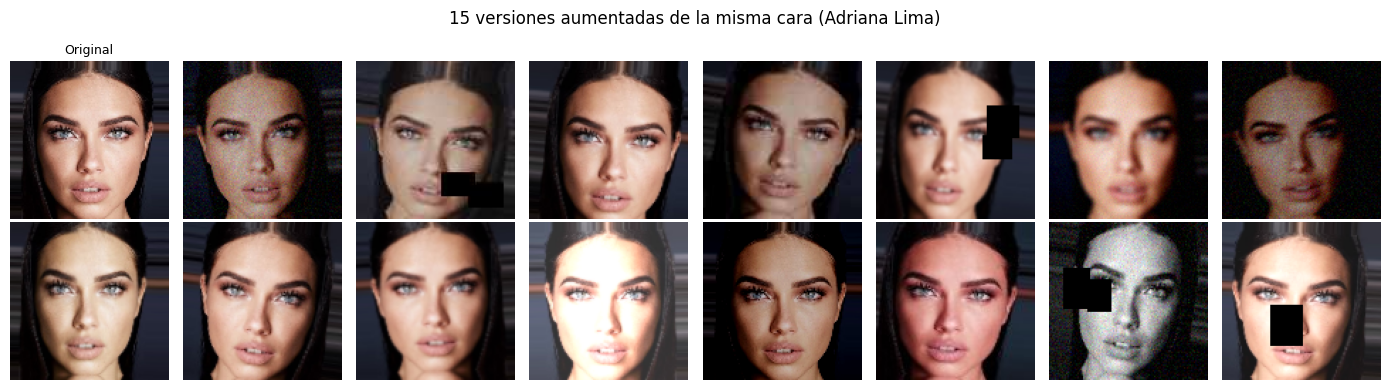

In [ ]:
original = caras_alineadas[int(curadas['idx_cara'].iloc[0])]
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
axes.flat[0].imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB)); axes.flat[0].set_title('Original', fontsize=9)
for ax in axes.flat[1:]:
    ax.imshow(cv2.cvtColor(aumentacion(image=original)['image'], cv2.COLOR_BGR2RGB))
for ax in axes.flat: ax.axis('off')
plt.suptitle(f'15 versiones aumentadas de la misma cara ({curadas["identidad"].iloc[0]})'); plt.tight_layout(); plt.show()

**Resultado:** las 15 versiones muestran las variaciones del pipeline: cambios de brillo y contraste, tono rosado o cálido, escala de grises, desenfoque, ruido, pequeñas rotaciones y rectángulos negros que simulan oclusiones sobre un ojo, la mejilla o la boca. En todas, **la persona sigue siendo reconocible**: las transformaciones cambian las condiciones de la foto pero no los rasgos que la identifican.

*Observación:* en los costados de la cara alineada se ven franjas verticales. Son el efecto del borde que repite los píxeles del contorno (sección 3.1), necesario porque los recortes de Pins son muy ajustados. Quedan en el fondo, fuera de la zona de ojos, nariz y boca.

## 7. Partición de datos
Se distinguen los dos escenarios del problema:
- **Closed-set (identificación):** las mismas personas en train y test, con fotos distintas. Mide si el modelo reconoce a las personas con las que se entrenó.
- **Open-set (verificación):** personas que el modelo **nunca vio**. Es el escenario real de la app, donde se registran personas nuevas.

**Estrategia:**
1. Se reservan **20 identidades al azar** para el test open-set. No se usan para entrenar ni para validar.
2. Con las **85 identidades restantes**, las fotos de cada persona se reparten en **80% train, 10% validación y 10% test closed-set**, de forma **estratificada** (cada persona mantiene esas proporciones).
3. Se fija la semilla (`42`) para que la partición sea reproducible, y se guarda en `splits.csv` para que la notebook 2 use exactamente los mismos datos.

**Por qué 80/10/10:** cada persona tiene en promedio unas 160 fotos, así que el 10% deja unas 16 fotos por persona en validación y en test: suficientes para evaluar, dejando la mayoría para entrenar.

In [ ]:
from sklearn.model_selection import train_test_split
SEMILLA = 42
N_OPEN = 20  # identidades reservadas que el modelo nunca ve en el entrenamiento

identidades = np.sort(curadas['identidad'].unique())
ids_open = np.random.default_rng(SEMILLA).choice(identidades, N_OPEN, replace=False)
ids_closed = np.setdiff1d(identidades, ids_open)

closed = curadas[curadas['identidad'].isin(ids_closed)]
train, resto = train_test_split(closed, test_size=0.2, stratify=closed['identidad'], random_state=SEMILLA)
val, test_closed = train_test_split(resto, test_size=0.5, stratify=resto['identidad'], random_state=SEMILLA)
test_open = curadas[curadas['identidad'].isin(ids_open)]

splits = pd.concat([train.assign(split='train'), val.assign(split='val'),
                    test_closed.assign(split='test_closed'), test_open.assign(split='test_open')])
splits = splits[['ruta', 'identidad', 'idx_cara', 'split']].reset_index(drop=True)

resumen_splits = splits.groupby('split').agg(identidades=('identidad', 'nunique'), imagenes=('ruta', 'size'))
resumen_splits = resumen_splits.loc[['train', 'val', 'test_closed', 'test_open']]
resumen_splits['% imágenes'] = (100 * resumen_splits['imagenes'] / len(splits)).round(1)
print(resumen_splits.to_string())
print(f'\nIdentidades open-set (nunca vistas en entrenamiento): {", ".join(sorted(ids_open))}')

             identidades  imagenes  % imágenes
split                                         
train                 85     11094        65.7
val                   85      1387         8.2
test_closed           85      1387         8.2
test_open             20      3020        17.9

Identidades open-set (nunca vistas en entrenamiento): Anthony Mackie, Avril Lavigne, Brian J. Smith, Christian Bale, Jimmy Fallon, Johnny Depp, Lindsey Morgan, Madelaine Petsch, Maria Pedraza, Miley Cyrus, Neil Patrick Harris, Rami Malek, Robert De Niro, Robert Downey Jr, Shakira Isabel Mebarak, Taylor Swift, Tom Cruise, Zendaya, barack obama, elizabeth olsen


**Resultado:**
| Split | Identidades | Imágenes | % |
|---|---|---|---|
| train | 85 | 11.094 | 65,7% |
| val | 85 | 1.387 | 8,2% |
| test_closed | 85 | 1.387 | 8,2% |
| test_open | 20 | 3.020 | 17,9% |

- Las **85 identidades closed-set** aparecen en train, validación y test con **fotos distintas** (80/10/10 estratificado).
- Las **20 identidades open-set** (por ejemplo Barack Obama, Taylor Swift o Robert De Niro) solo aparecen en `test_open`: el modelo **nunca las ve durante el entrenamiento**. Con ellas se evalúa la verificación y el reconocimiento de personas nuevas, que es el escenario real de la app.

*Observación:* algunas identidades open-set (Robert Downey Jr, Johnny Depp, Zendaya) fueron justamente las que aparecieron confundidas en las etiquetas erróneas de la sección 5. Esas imágenes ya se descartaron, así que no afectan la evaluación.

### 7.2 Verificación de ausencia de fuga de datos
Se verifica que ninguna imagen de validación o test tenga un casi-duplicado en train (similitud > 0,95), que ninguna identidad open-set aparezca en train y que no haya rutas repetidas entre splits.

In [ ]:
emb_split = {s: emb_todas[splits.loc[splits['split'] == s, 'idx_cara'].astype(int)] for s in ['train', 'val', 'test_closed', 'test_open']}

def max_similitud(a, b, lote=2048):
    # Para cada imagen de a, la similitud con su imagen más parecida de b
    return np.concatenate([(a[i:i + lote] @ b.T).max(axis=1) for i in range(0, len(a), lote)])

print('Chequeo de fuga: imágenes de evaluación con un casi-duplicado (similitud > 0.95) en train')
for s in ['val', 'test_closed', 'test_open']:
    sims = max_similitud(emb_split[s], emb_split['train'])
    print(f'  {s:12s}: {(sims > UMBRAL_DUPLICADO).sum()} de {len(sims)} | similitud máxima: {sims.max():.3f}')
print(f'\nIdentidades compartidas entre train y test_open: {len(set(train["identidad"]) & set(ids_open))}')
print(f'Rutas repetidas entre splits: {splits["ruta"].duplicated().sum()}')

Chequeo de fuga: imágenes de evaluación con un casi-duplicado (similitud > 0.95) en train
  val         : 0 de 1387 | similitud máxima: 0.950
  test_closed : 0 de 1387 | similitud máxima: 0.950
  test_open   : 0 de 3020 | similitud máxima: 0.419

Identidades compartidas entre train y test_open: 0
Rutas repetidas entre splits: 0


**Resultado:**
- **Validación y test closed-set:** ninguna imagen tiene un casi-duplicado en train por encima del umbral (0 de 1.387 en cada uno). La similitud máxima es **0,950**, justo el valor del umbral: hay algunas fotos muy parecidas a otra de train (por ejemplo, dos fotos de la misma sesión), pero no copias de la misma imagen, que fueron eliminadas en la sección 3.
- **Test open-set:** la similitud máxima con train es **0,419**, muy baja, como se espera de personas distintas. **No hay ninguna identidad compartida** entre train y test_open.
- No hay rutas repetidas entre splits.

**Conclusión:** no hay fuga de datos. El escenario open-set, que es el más importante para la app, está completamente separado del entrenamiento.

In [ ]:
splits.to_csv(f'{PROCESADO}/splits.csv', index=False)
print('Guardado:', f'{PROCESADO}/splits.csv')

Guardado: /content/drive/MyDrive/TP_FaceRec/procesado/splits.csv


## 8. Ética, privacidad y licencias

**Licencia del dataset.** Pins Face Recognition se publica en Kaggle con licencia **CC0-1.0** (dominio público), que permite su uso. Sin embargo, el dataset es una **recopilación de fotos de Pinterest**: la licencia de la recopilación no garantiza los derechos de autor de cada fotografía individual, que pertenecen a sus autores. Por eso se usa **solo con fines académicos**, y las imágenes **no se suben al repositorio** (el `.gitignore` excluye `data/*`).

**Licencia de los modelos.** Los modelos preentrenados de InsightFace (`buffalo_l`) son de **uso no comercial / investigación**, compatible con este trabajo práctico pero no con un producto comercial.

**Datos biométricos.** Un rostro es un **dato biométrico**: identifica a una persona de forma única y no se puede "cambiar" como una contraseña. En Argentina, la **Ley 25.326 de Protección de Datos Personales** exige el **consentimiento libre, expreso e informado** del titular para tratar sus datos personales. Según la **Resolución 4/2019 de la AAIP**, los datos biométricos se consideran **datos sensibles** (con protección reforzada) cuando su uso puede dar lugar a discriminación, por ejemplo si revelan el origen étnico o información de salud. En este trabajo:
- Las imágenes del dataset son de **personas públicas** y se usan solo para entrenar y evaluar.
- Para probar la app solo se usan fotos de celebridades del dataset o fotos propias. **No se registran personas sin su consentimiento informado**, y las fotos de prueba no se suben al repositorio.

**Sesgos del dataset y su impacto.**
- **Demográficos:** son celebridades, mayormente **occidentales, de piel clara y adultos jóvenes**. Están subrepresentadas las personas de piel oscura, de origen asiático, mayores y niños. Es esperable que **los modelos funcionen peor en esos grupos**, con más falsos positivos (confundir a dos personas) o falsos negativos (no reconocer a alguien).
- **Tipo de imagen:** predominan fotos profesionales, maquilladas y retocadas, distintas de una foto de cámara de seguridad o de celular con mala luz.
- **ArcFace** también fue entrenado con fotos de internet de celebridades, por lo que hereda sesgos similares.

**Riesgos del reconocimiento facial.** Es una tecnología que puede usarse para **vigilancia masiva** y seguimiento de personas sin su conocimiento. Los errores (por ejemplo, un falso positivo que identifica como sospechosa a una persona inocente) pueden tener consecuencias graves, y suelen afectar más a los grupos subrepresentados. Por eso, un sistema real requiere consentimiento, transparencia sobre su uso, un umbral elegido según el costo de cada tipo de error, supervisión humana en decisiones importantes y evaluación del desempeño por grupo demográfico.

## Resumen final
| Etapa | Imágenes | Identidades |
|---|---|---|
| Dataset original (Pins) | 17.534 | 105 |
| Tras las reglas de calidad (sección 3) | 16.894 | 105 |
| Tras descartar etiquetas erróneas (sección 5) | **16.888** | **105** |

| Split | Identidades | Imágenes | Uso |
|---|---|---|---|
| train | 85 | 11.094 | Entrenar la CNN (con augmentation) |
| val | 85 | 1.387 | Early stopping y calibración del umbral |
| test_closed | 85 | 1.387 | Identificación de personas conocidas |
| test_open | 20 | 3.020 | Verificación e identificación de personas nunca vistas |

**Archivos generados en Drive (`TP_FaceRec/procesado/`), que usa la notebook 2:**
- `caras_alineadas.npy`: caras alineadas 112×112 (BGR).
- `embeddings_arcface.npy`: embeddings ArcFace normalizados L2.
- `curadas.pkl` y `procesamiento.pkl`: tablas con las imágenes curadas y el motivo de descarte de cada imagen.
- `splits.csv`: partición train / val / test_closed / test_open.